# 🎓 Grade Prediction — AI Feature 
### Educational ERP Intelligence Module

---

**Purpose:** Predict the letter grade and numeric score a student will earn in a target course, before they enroll, using their full transcript history.

**Model:** XGBoost Regressor (numeric grade 0–4.0) → Grade Mapping Layer → Letter grade + Confidence



---

## 📋 Notebook Structure
1. [Imports & Configuration](#1)
2. [Prerequisite Catalog — Loaded from Transcript Generator](#2)
3. [Grade & Domain Utilities](#3)
4. [Transcript Loading & Semester Ordering](#4)
5. [Feature Engineering](#5)
6. [Training Dataset Construction](#6)
7. [Model Training & Cross-Validation](#7)
8. [Prediction Pipeline (matches spec I/O exactly)](#8)
9. [SHAP Explainability](#9)
10. [Validation & Edge-Case Test Suite](#10)
11. [Model Evaluation Summary](#11)

<a id='1'></a>
## 1 · Imports & Configuration

In [3]:
import json
import re
import warnings
from pathlib import Path
from collections import defaultdict
from typing import Dict, List, Optional, Tuple


import numpy as np
import pandas as pd


from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score, KFold, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder


try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("⚠️  SHAP not installed — explainability section will be skipped.")


import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.4f}'.format)

TRANSCRIPT_FILE = Path('transcripts.json')



<a id='2'></a>
## 2 · Prerequisite Catalog

In [4]:
_COURSE_CATALOG_RAW = {
    # ── MATH ──────────────────────────────────────────────────────────────────
    "MATH 101": {"name": "Calculus I",                        "credits": 3, "prerequisites": []},
    "MATH 102": {"name": "Calculus II",                       "credits": 3, "prerequisites": ["MATH 101"]},
    "MATH 103": {"name": "Calculus for Computational Sciences","credits": 3, "prerequisites": []},
    "MATH 104": {"name": "Linear Algebra",                    "credits": 3, "prerequisites": []},
    "MATH 105": {"name": "Probability and Statistics",        "credits": 3, "prerequisites": ["MATH 103"]},
    "MATH 201": {"name": "Linear Algebra and Vector Geometry","credits": 3, "prerequisites": []},
    "MATH 202": {"name": "Ordinary Differential Equations",   "credits": 3, "prerequisites": ["MATH 102"]},
    "MATH 203": {"name": "Introduction to Discrete Mathematics","credits":1,"prerequisites": []},
    "MATH 205": {"name": "Discrete Mathematics for Computational Sciences","credits":3,"prerequisites":[]},
    "MATH 301": {"name": "Probability and Statistics",        "credits": 3, "prerequisites": ["MATH 102"]},
    "MATH 302": {"name": "PDEs and Complex Analysis",         "credits": 3, "prerequisites": ["MATH 202"]},
    "MATH 303": {"name": "Linear and Non-linear Programming","credits": 3, "prerequisites": ["MATH 103","MATH 104"]},
    "MATH 305": {"name": "Abstract Algebra",                 "credits": 3, "prerequisites": ["MATH 201"]},
    "MATH 306": {"name": "Numerical Analysis",               "credits": 3, "prerequisites": ["MATH 201","MATH 202"]},
    "MATH 307": {"name": "Numerical Methods",                "credits": 3, "prerequisites": ["MATH 104"]},
    "MATH 308": {"name": "Discrete Mathematics",             "credits": 3, "prerequisites": []},
    "MATH 310": {"name": "Abstract Algebra",                 "credits": 3, "prerequisites": ["MATH 201"]},
    "MATH 403": {"name": "Real Analysis and Topology",       "credits": 3, "prerequisites": ["MATH 101","MATH 201"]},
    "MATH 404": {"name": "Linear and Non-linear Programming","credits": 3, "prerequisites": ["MATH 102"]},
    # ── PHYS ──────────────────────────────────────────────────────────────────
    "PHYS 101": {"name": "Introduction to Classical Mechanics","credits":3,"prerequisites":[]},
    "PHYS 102": {"name": "Introduction to Electromagnetism",  "credits":3,"prerequisites":["PHYS 101","MATH 101"]},
    "PHYS 103": {"name": "Physics 1",                         "credits":3,"prerequisites":["MATH 103"]},
    "PHYS 104": {"name": "Physics 2",                         "credits":3,"prerequisites":[]},
    "PHYS 105": {"name": "Classical Mechanics for Engineers", "credits":3,"prerequisites":[]},
    "PHYS 106": {"name": "Electromagnetism for Engineers",    "credits":3,"prerequisites":["PHYS 115","PHYS 105"]},
    "PHYS 111": {"name": "Classical Mechanics Lab",           "credits":1,"prerequisites":[]},
    "PHYS 112": {"name": "Electromagnetism Lab",              "credits":1,"prerequisites":[]},
    "PHYS 115": {"name": "Classical Mechanics (Lab)",         "credits":1,"prerequisites":[]},
    "PHYS 116": {"name": "Electromagnetism (Lab)",            "credits":1,"prerequisites":[]},
    "PHYS 125": {"name": "Classical Mechanics (Theory)",      "credits":2,"prerequisites":[]},
    "PHYS 126": {"name": "Electromagnetism (Theory)",         "credits":2,"prerequisites":["PHYS 125","PHYS 105"]},
    "PHYS 201": {"name": "Thermodynamics, Wave Motion and Optics","credits":3,"prerequisites":["PHYS 102"]},
    "PHYS 202": {"name": "Modern Physics",                   "credits":3,"prerequisites":["PHYS 102"]},
    "PHYS 203": {"name": "Thermodynamics for Engineers",     "credits":3,"prerequisites":["PHYS 105","PHYS 125"]},
    "PHYS 204": {"name": "Analytical Mechanics",             "credits":3,"prerequisites":["PHYS 101"]},
    "PHYS 205": {"name": "Introduction to Modern Astrophysics","credits":3,"prerequisites":["PHYS 101"]},
    "PHYS 211": {"name": "Thermodynamics Lab",               "credits":1,"prerequisites":[]},
    "PHYS 212": {"name": "Modern Physics Lab",               "credits":1,"prerequisites":[]},
    "PHYS 218": {"name": "Vector Calculus",                  "credits":3,"prerequisites":["MATH 102"]},
    "PHYS 224": {"name": "Modern Physics for Engineers",     "credits":3,"prerequisites":["PHYS 203"]},
    "PHYS 311": {"name": "Thermal and Statistical Physics",  "credits":3,"prerequisites":["PHYS 201"]},
    "PHYS 316": {"name": "Mathematical Physics I",           "credits":3,"prerequisites":[]},
    "PHYS 323": {"name": "Quantum Mechanics I",              "credits":3,"prerequisites":["PHYS 202"]},
    "PHYS 327": {"name": "Observational Astrophysics Lab",   "credits":2,"prerequisites":["PHYS 205"]},
    "PHYS 331": {"name": "Stellar Structure and Evolution",  "credits":3,"prerequisites":["PHYS 205"]},
    "PHYS 346": {"name": "Mathematical Physics I",           "credits":3,"prerequisites":["MATH 202"]},
    "PHYS 348": {"name": "Quantum Mechanics II",             "credits":3,"prerequisites":["PHYS 323"]},
    "PHYS 356": {"name": "Mathematical Physics II",          "credits":4,"prerequisites":["MATH 201"]},
    "PHYS 405": {"name": "Cosmology",                        "credits":3,"prerequisites":["PHYS 205"]},
    "PHYS 416": {"name": "Galactic Astrophysics",            "credits":3,"prerequisites":["PHYS 205"]},
    "PHYS 430": {"name": "Quantum Mechanics III",            "credits":3,"prerequisites":["PHYS 348"]},
    "PHYS 431": {"name": "Quantum Field Theory",             "credits":6,"prerequisites":["PHYS 323"]},
    "PHYS 438": {"name": "Compact Objects Astrophysics",     "credits":3,"prerequisites":["PHYS 205"]},
    "PHYS 450": {"name": "Computational Physics",            "credits":3,"prerequisites":["CSCI 101"]},
    "PHYS 498": {"name": "Senior Project I",                 "credits":1,"prerequisites":[]},
    "PHYS 499": {"name": "Senior Project II",                "credits":2,"prerequisites":["PHYS 498"]},
    # ── CHEM ──────────────────────────────────────────────────────────────────
    "CHEM 101": {"name": "Chemistry I",           "credits":3,"prerequisites":[]},
    "CHEM 102": {"name": "Chemistry II",          "credits":3,"prerequisites":["CHEM 101"]},
    "CHEM 103": {"name": "Chemistry for Engineers","credits":3,"prerequisites":[]},
    "CHEM 111": {"name": "Chemistry I Lab",       "credits":1,"prerequisites":[]},
    "CHEM 112": {"name": "Chemistry II Lab",      "credits":1,"prerequisites":[]},
    "CHEM 201": {"name": "Organic Chemistry",     "credits":3,"prerequisites":["CHEM 101"]},
    "CHEM 202": {"name": "Analytical & Physical Chemistry","credits":3,"prerequisites":["CHEM 101"]},
    "CHEM 203": {"name": "Organic Chemistry II",  "credits":3,"prerequisites":["CHEM 201"]},
    "CHEM 211": {"name": "Organic Chemistry Lab", "credits":1,"prerequisites":[]},
    "CHEM 212": {"name": "Analytical Chemistry Lab","credits":1,"prerequisites":[]},
    # ── BIOL ──────────────────────────────────────────────────────────────────
    "BIOL 101": {"name": "Biology I",    "credits":3,"prerequisites":[]},
    "BIOL 102": {"name": "Biology II",   "credits":3,"prerequisites":["BIOL 101"]},
    "BIOL 111": {"name": "Biology I Lab","credits":1,"prerequisites":[]},
    "BIOL 112": {"name": "Biology II Lab","credits":1,"prerequisites":[]},
    # ── CSCI / CSAI ───────────────────────────────────────────────────────────
    "CSCI 101":  {"name": "Introduction to Computing",          "credits":3,"prerequisites":[]},
    "CSAI 100":  {"name": "Introduction to Computing",          "credits":3,"prerequisites":[]},
    "CSAI 101":  {"name": "Programming I",                      "credits":3,"prerequisites":[]},
    "CSAI 102":  {"name": "Programming II",                     "credits":3,"prerequisites":["CSAI 101"]},
    "CSAI 151":  {"name": "Data Structures",                    "credits":3,"prerequisites":["CSAI 101"]},
    "CSAI 201":  {"name": "Object-Oriented Programming",        "credits":3,"prerequisites":["CSAI 101"]},
    "CSAI 202":  {"name": "Database Systems",                   "credits":3,"prerequisites":["CSAI 101"]},
    "CSAI 203":  {"name": "Software Engineering",               "credits":3,"prerequisites":["CSAI 151"]},
    "CSAI 204":  {"name": "Operating Systems",                  "credits":3,"prerequisites":["CSAI 201"]},
    "CSAI 205":  {"name": "Computer Networks",                  "credits":3,"prerequisites":["CSAI 101"]},
    "CSAI 251":  {"name": "Algorithms",                         "credits":3,"prerequisites":["CSAI 151"]},
    "CSAI 252":  {"name": "Computer Organization",              "credits":3,"prerequisites":[]},
    "CSAI 253":  {"name": "Machine Learning",                   "credits":3,"prerequisites":["CSAI 202","MATH 105"]},
    "CSAI 301":  {"name": "Artificial Intelligence",            "credits":3,"prerequisites":["CSAI 253"]},
    "CSAI 302":  {"name": "Advanced AI",                        "credits":3,"prerequisites":["CSAI 301"]},
    "CSAI 351":  {"name": "Computer Graphics",                  "credits":3,"prerequisites":["CSAI 201"]},
    "CSAI 399":  {"name": "Internship",                         "credits":3,"prerequisites":[]},
    "CSAI 498":  {"name": "Senior Design Project I",            "credits":1,"prerequisites":[]},
    "CSAI 499":  {"name": "Senior Design Project II",           "credits":3,"prerequisites":["CSAI 498"]},
    # ── DSAI ──────────────────────────────────────────────────────────────────
    "DSAI 103":  {"name": "Data Acquisition (ETL)",             "credits":3,"prerequisites":["CSAI 101"]},
    "DSAI 104":  {"name": "Knowledge Representation",           "credits":2,"prerequisites":["CSAI 101"]},
    "DSAI 201":  {"name": "Data Mining and IR",                 "credits":3,"prerequisites":["CSAI 202"]},
    "DSAI 202":  {"name": "Data Governance",                    "credits":2,"prerequisites":[]},
    "DSAI 203":  {"name": "Data Integration and Visualization", "credits":3,"prerequisites":[]},
    "DSAI 305":  {"name": "Interpretability in AI",             "credits":3,"prerequisites":["CSAI 253"]},
    "DSAI 307":  {"name": "Statistical Inference",              "credits":2,"prerequisites":["MATH 105"]},
    "DSAI 308":  {"name": "Deep Learning",                      "credits":3,"prerequisites":["CSAI 253"]},
    "DSAI 325":  {"name": "Information Theory",                 "credits":3,"prerequisites":["MATH 105"]},
    "DSAI 352":  {"name": "Computer Vision",                    "credits":3,"prerequisites":["DSAI 308"]},
    "DSAI 353":  {"name": "Natural Language Processing",        "credits":3,"prerequisites":["DSAI 308"]},
    "DSAI 402":  {"name": "Reinforcement Learning",             "credits":3,"prerequisites":["DSAI 308"]},
    "DSAI 403":  {"name": "Nature Inspired Computation",        "credits":3,"prerequisites":[]},
    "DSAI 406":  {"name": "MLOps",                              "credits":3,"prerequisites":["DSAI 308"]},
    "DSAI 427":  {"name": "Big Data Analytics",                 "credits":3,"prerequisites":["CSAI 253"]},
    "DSAI 456":  {"name": "Speech Recognition",                 "credits":3,"prerequisites":[]},
    # ── SW / SWAPD / SWGCG / SWHCI ────────────────────────────────────────────
    "SW 151":    {"name": "Computer Architecture",              "credits":3,"prerequisites":["CSAI 102"]},
    "SW 251":    {"name": "UX and Interaction Design",          "credits":3,"prerequisites":[]},
    "SW 252":    {"name": "Embedded Systems",                   "credits":3,"prerequisites":["SW 151"]},
    "SW 301":    {"name": "OO Analysis and Design",             "credits":3,"prerequisites":["CSAI 151"]},
    "SW 302":    {"name": "User Interface Development",         "credits":3,"prerequisites":["SW 251"]},
    "SW 401":    {"name": "Parallel and Distributed Computing", "credits":3,"prerequisites":["CSAI 151"]},
    "SW 402":    {"name": "Software Project Management",        "credits":3,"prerequisites":[]},
    "SW 403":    {"name": "AI in Modern Software Engineering",  "credits":3,"prerequisites":["CSAI 203","CSAI 253"]},
    "SWAPD 301": {"name": "Software Requirements",             "credits":3,"prerequisites":["CSAI 203"]},
    "SWAPD 351": {"name": "Software Architecture",             "credits":3,"prerequisites":["CSAI 203"]},
    "SWAPD 352": {"name": "Web Application Development",       "credits":3,"prerequisites":["CSAI 202"]},
    "SWAPD 401": {"name": "Software Testing & QA",             "credits":3,"prerequisites":[]},
    "SWAPD 402": {"name": "Mobile Application Development",    "credits":3,"prerequisites":["CSAI 201"]},
    "SWAPD 452": {"name": "Enterprise Application Development","credits":3,"prerequisites":["CSAI 202"]},
    "SWAPD 453": {"name": "IoT Applications Development",      "credits":3,"prerequisites":["CSAI 252"]},
    "SWGCG 301": {"name": "Computer Graphics and Multimedia",  "credits":3,"prerequisites":["CSAI 201"]},
    "SWGCG 351": {"name": "Game Design and Development",       "credits":3,"prerequisites":[]},
    "SWGCG 352": {"name": "Physics-Based Animation",           "credits":3,"prerequisites":["SWGCG 301"]},
    "SWGCG 402": {"name": "Visual Effects Production",         "credits":3,"prerequisites":["SWGCG 352"]},
    "SWHCI 301": {"name": "Prototyping Algorithmic Experiences","credits":3,"prerequisites":["CSAI 251"]},
    "SWHCI 351": {"name": "Statistical Graphics and Visualization","credits":3,"prerequisites":["MATH 105"]},
    "SWHCI 352": {"name": "User-Focused Sensing Systems",      "credits":3,"prerequisites":["SW 251"]},
    "SWHCI 401": {"name": "HCI and AI",                        "credits":3,"prerequisites":["CSAI 301"]},
    "SWHCI 402": {"name": "AI Based Products",                 "credits":3,"prerequisites":["CSAI 301"]},
    # ── IT ─────────────────────────────────────────────────────────────────────
    "IT 101":    {"name": "Shell and Script Programming",       "credits":2,"prerequisites":["CSAI 101"]},
    "IT 102":    {"name": "Ethical Hacking and Defense",        "credits":2,"prerequisites":["CSAI 101"]},
    "IT 103":    {"name": "Fundamentals of ICT",               "credits":2,"prerequisites":[]},
    "IT 205":    {"name": "Enterprise System Architecture",     "credits":2,"prerequisites":[]},
    "IT 206":    {"name": "IT Governance and Risk Management",  "credits":2,"prerequisites":[]},
    "IT 220":    {"name": "Networks Installation",              "credits":2,"prerequisites":["CSAI 252"]},
    "IT 222":    {"name": "Multimedia Creation",               "credits":2,"prerequisites":["CSAI 252"]},
    "IT 308":    {"name": "Cloud Computing Architecture",       "credits":2,"prerequisites":["CSAI 201"]},
    "IT 309":    {"name": "IT UX Design",                      "credits":3,"prerequisites":[]},
    "IT 310":    {"name": "Cybersecurity Foundations",          "credits":3,"prerequisites":["CSAI 252"]},
    "IT 402":    {"name": "Cybersecurity and Encryption",       "credits":3,"prerequisites":[]},
    "IT 411":    {"name": "Enterprise Resources Planning",      "credits":3,"prerequisites":[]},
    "ITNS 301":  {"name": "Network Administration",             "credits":2,"prerequisites":["CSAI 252"]},
    "ITNS 302":  {"name": "IoT Systems Development",            "credits":3,"prerequisites":["CSAI 252"]},
    "ITNS 407":  {"name": "IT Audit and Risk Management",       "credits":3,"prerequisites":[]},
    "ITNS 408":  {"name": "Network Security",                   "credits":3,"prerequisites":["IT 310"]},
    "ITNS 410":  {"name": "Penetration Testing",                "credits":3,"prerequisites":[]},
    "ITCC 301":  {"name": "Linux System Administration",        "credits":2,"prerequisites":[]},
    "ITCC 302":  {"name": "Cloud Infrastructure Administration","credits":3,"prerequisites":["IT 308"]},
    "ITCC 403":  {"name": "Security Testing for Cloud",        "credits":3,"prerequisites":["IT 310"]},
    "ITCC 405":  {"name": "Virtualization and Cloud Security",  "credits":3,"prerequisites":["IT 308"]},
    # ── BMS ───────────────────────────────────────────────────────────────────
    "BMS 201":   {"name": "General Microbiology",         "credits":3,"prerequisites":["BIOL 102"]},
    "BMS 202":   {"name": "Cell Biology",                  "credits":3,"prerequisites":["BIOL 102"]},
    "BMS 203":   {"name": "Principles of Genetics",       "credits":3,"prerequisites":["BIOL 102"]},
    "BMS 204":   {"name": "Biochemistry",                  "credits":3,"prerequisites":["CHEM 201"]},
    "BMS 205":   {"name": "Human Physiology",              "credits":3,"prerequisites":["BIOL 102"]},
    "BMS 211":   {"name": "Microbiology Lab",              "credits":1,"prerequisites":[]},
    "BMS 212":   {"name": "Cell Biology Lab",              "credits":1,"prerequisites":[]},
    "BMS 213":   {"name": "Genetics Lab",                  "credits":1,"prerequisites":[]},
    "BMS 214":   {"name": "Biochemistry Lab",              "credits":1,"prerequisites":[]},
    "BMS 301":   {"name": "Molecular Biology",             "credits":3,"prerequisites":["BMS 202"]},
    "BMS 302":   {"name": "Functional Genomics",           "credits":3,"prerequisites":["BMS 202","BMS 203","BMS 204"]},
    "BMS 303":   {"name": "Experimental Design",           "credits":3,"prerequisites":["BIOL 102"]},
    "BMS 304":   {"name": "Biomedical Ethics",             "credits":2,"prerequisites":["BIOL 102"]},
    "BMS 320":   {"name": "Introduction to Bioinformatics","credits":3,"prerequisites":["BIOL 102","CSCI 101","MATH 102"]},
    "BMS 399":   {"name": "Internship",                    "credits":2,"prerequisites":[]},
    "BMS 401":   {"name": "Senior Project I",              "credits":3,"prerequisites":[]},
    "BMS 402":   {"name": "Senior Project II",             "credits":3,"prerequisites":[]},
    "BMS 404":   {"name": "Biostatistics",                 "credits":3,"prerequisites":["BIOL 101"]},
    # ── NANOSC ────────────────────────────────────────────────────────────────
    "NANOSC 302":{"name": "Modern Characterization Techniques I","credits":3,"prerequisites":[]},
    "NANOSC 305":{"name": "Synthesis/Fabrication of Nanomaterials","credits":3,"prerequisites":[]},
    "NANOSC 307":{"name": "Nanosciences Research Lab",           "credits":1,"prerequisites":[]},
    "NANOSC 399":{"name": "Internship",                          "credits":2,"prerequisites":[]},
    "NANOSC 458":{"name": "Capstone Research I",                  "credits":3,"prerequisites":[]},
    "NANOSC 498":{"name": "Capstone Research II",                  "credits":3,"prerequisites":[]},
    # ── MATSCI ────────────────────────────────────────────────────────────────
    "MATSCI 201":{"name": "Fundamentals of Materials Science","credits":3,"prerequisites":["CHEM 101","PHYS 101"]},
    "MATSCI 204":{"name": "Inorganic Chemistry",              "credits":3,"prerequisites":["CHEM 102"]},
    "MATSCI 302":{"name": "Solid State Physics",              "credits":3,"prerequisites":["PHYS 102"]},
    "MATSCI 303":{"name": "Macromolecular Chemistry",         "credits":3,"prerequisites":[]},
    "MATSCI 304":{"name": "Modern Characterization II",       "credits":3,"prerequisites":[]},
    "MATSCI 307":{"name": "Scientific Computing",             "credits":3,"prerequisites":[]},
    "MATSCI 399":{"name": "Internship",                        "credits":2,"prerequisites":[]},
    "MATSCI 480":{"name": "Self-assembled Systems",            "credits":3,"prerequisites":[]},
    # ── CIE ───────────────────────────────────────────────────────────────────
    "CIE 101":   {"name": "Fundamentals of Computer Programming","credits":3,"prerequisites":["CSCI 101"]},
    "CIE 110":   {"name": "Introduction to Circuits",          "credits":3,"prerequisites":[]},
    "CIE 201":   {"name": "Advanced Electric Circuits",        "credits":3,"prerequisites":["MATH 202","CIE 110"]},
    "CIE 205":   {"name": "Data Structures and Algorithms",    "credits":3,"prerequisites":["CIE 101"]},
    "CIE 206":   {"name": "Database Management",              "credits":3,"prerequisites":["CIE 101"]},
    "CIE 227":   {"name": "Signals and Systems",               "credits":3,"prerequisites":["MATH 101"]},
    "CIE 237":   {"name": "Probability and Stochastic Processes","credits":3,"prerequisites":["MATH 201","CIE 227"]},
    "CIE 239":   {"name": "Digital Design and Computer Arch",  "credits":3,"prerequisites":[]},
    "CIE 247":   {"name": "Digital Signal Processing",         "credits":3,"prerequisites":["CIE 227"]},
    "CIE 249":   {"name": "Computer Architecture",             "credits":3,"prerequisites":["CIE 239"]},
    "CIE 302":   {"name": "Operating Systems",                 "credits":3,"prerequisites":["CIE 205"]},
    "CIE 317":   {"name": "Machine Learning",                  "credits":3,"prerequisites":["CIE 205","CIE 237"]},
    "CIE 318":   {"name": "Control Systems",                   "credits":3,"prerequisites":["CIE 227"]},
    "CIE 328":   {"name": "Electromagnetic Fields I",          "credits":3,"prerequisites":["MATH 102","PHYS 102"]},
    "CIE 337":   {"name": "Communications Theory",             "credits":3,"prerequisites":["CIE 237"]},
    "CIE 338":   {"name": "Electromagnetic Fields II",         "credits":3,"prerequisites":["CIE 328","MATH 302"]},
    "CIE 347":   {"name": "Information Theory and Coding",     "credits":3,"prerequisites":["CIE 237"]},
    "CIE 349":   {"name": "Embedded Systems",                  "credits":3,"prerequisites":["CIE 249","CIE 302"]},
    "CIE 357":   {"name": "Digital and Wireless Communications","credits":3,"prerequisites":["CIE 337"]},
    "CIE 367":   {"name": "Computer Networks",                 "credits":3,"prerequisites":["CIE 237"]},
    "CIE 399":   {"name": "Software Engineering",              "credits":2,"prerequisites":["CIE 205","CIE 206"]},
    "CIE 448":   {"name": "IoT Systems Engineering",           "credits":3,"prerequisites":["CIE 349","CIE 367"]},
    "CIE 498":   {"name": "Senior Design Project I",           "credits":1,"prerequisites":[]},
    "CIE 499":   {"name": "Senior Design Project II",          "credits":3,"prerequisites":["CIE 498"]},
    # ── ENGR ──────────────────────────────────────────────────────────────────
    "ENGR 102":  {"name": "Engineering Drawing",               "credits":1,"prerequisites":[]},
    "ENGR 105":  {"name": "Engineering Thermodynamics",        "credits":3,"prerequisites":[]},
    "ENGR 121":  {"name": "Workshop",                          "credits":1,"prerequisites":[]},
    "ENGR 201":  {"name": "Electric Circuits",                 "credits":3,"prerequisites":[]},
    "ENGR 207":  {"name": "Fluid Mechanics",                   "credits":3,"prerequisites":[]},
    "ENGR 333":  {"name": "Internship",                        "credits":3,"prerequisites":[]},
    "ENGR 346":  {"name": "Heat Transfer",                     "credits":3,"prerequisites":[]},
    # ── ENV ───────────────────────────────────────────────────────────────────
    "ENV 104":   {"name": "Chemistry for Environmental Engineers","credits":3,"prerequisites":["CHEM 103"]},
    "ENV 120":   {"name": "Microbiology and Environmental Health","credits":2,"prerequisites":[]},
    "ENV 204":   {"name": "Environmental Engineering Chemistry",  "credits":3,"prerequisites":["ENV 104"]},
    "ENV 207":   {"name": "Material and Energy Balances",        "credits":3,"prerequisites":[]},
    "ENV 219":   {"name": "Climate Dynamics",                    "credits":2,"prerequisites":[]},
    "ENV 224":   {"name": "Ecology for Environmental Engineers",  "credits":3,"prerequisites":[]},
    "ENV 230":   {"name": "Phase Equilibria",                    "credits":3,"prerequisites":["ENGR 105"]},
    "ENV 250":   {"name": "Hydraulic Engineering",               "credits":3,"prerequisites":["ENGR 207"]},
    "ENV 257":   {"name": "Reactions Engineering",               "credits":3,"prerequisites":["ENV 207"]},
    "ENV 302":   {"name": "Environmental Laws and Policies",      "credits":2,"prerequisites":[]},
    "ENV 306":   {"name": "Engineering Hydrology",               "credits":3,"prerequisites":["ENV 250","MATH 301"]},
    "ENV 320":   {"name": "Water Treatment Engineering",         "credits":3,"prerequisites":["ENV 204","ENV 250"]},
    "ENV 322":   {"name": "Wastewater Treatment Engineering",    "credits":3,"prerequisites":["ENV 120","ENV 204"]},
    "ENV 323":   {"name": "Municipal Solid Waste Management",    "credits":3,"prerequisites":["ENV 207"]},
    "ENV 325":   {"name": "Mass Transfer Operations",            "credits":3,"prerequisites":["ENGR 346"]},
    "ENV 367":   {"name": "Environmental Impact Assessment",     "credits":3,"prerequisites":["ENV 302"]},
    "ENV 380":   {"name": "Urban Water Systems Design",          "credits":3,"prerequisites":["ENV 306","ENV 320"]},
    "ENV 411":   {"name": "Process Synthesis and Simulation",    "credits":3,"prerequisites":["ENV 230","ENV 325"]},
    "ENV 412":   {"name": "Sustainability for Engineers",        "credits":2,"prerequisites":["ENV 302"]},
    "ENV 434":   {"name": "Safety and Risk Analysis",            "credits":3,"prerequisites":["MATH 301","ENGR 207"]},
    "ENV 440":   {"name": "Advanced Separation Processes",       "credits":3,"prerequisites":["ENV 325"]},
    "ENV 446":   {"name": "Water Desalination",                  "credits":3,"prerequisites":["ENV 320","ENV 440"]},
    "ENV 460":   {"name": "Water Quality Engineering",           "credits":2,"prerequisites":["ENV 204","ENV 306"]},
    "ENV 470":   {"name": "Air Quality and Pollution Engineering","credits":3,"prerequisites":["ENV 319","ENV 207"]},
    "ENV 498":   {"name": "Senior Design Project I",             "credits":1,"prerequisites":[]},
    "ENV 499":   {"name": "Senior Design Project II",            "credits":3,"prerequisites":["ENV 498"]},
    # ── NANENG ────────────────────────────────────────────────────────────────
    "NANENG 112":{"name": "C/C++ Programming Lab",              "credits":1,"prerequisites":["CSCI 101"]},
    "NANENG 171":{"name": "Materials Properties for Nanoelectronics","credits":2,"prerequisites":["CHEM 102"]},
    "NANENG 202":{"name": "Digital Logic",                      "credits":3,"prerequisites":[]},
    "NANENG 203":{"name": "Electric Circuits",                  "credits":3,"prerequisites":["MATH 102"]},
    "NANENG 205":{"name": "Physics of Semiconductors",          "credits":3,"prerequisites":["PHYS 224","MATH 202"]},
    "NANENG 212":{"name": "Applied Digital Control",            "credits":3,"prerequisites":["NANENG 112","MATH 202"]},
    "NANENG 222":{"name": "Electronic Circuit Design",          "credits":3,"prerequisites":["NANENG 203"]},
    "NANENG 231":{"name": "Electromagnetics",                   "credits":3,"prerequisites":["MATH 202","PHYS 106"]},
    "NANENG 301":{"name": "Micro/Nano Fabrication Techniques",  "credits":3,"prerequisites":["NANENG 171"]},
    "NANENG 308":{"name": "Solid State Devices",                "credits":3,"prerequisites":["NANENG 205"]},
    "NANENG 315":{"name": "MEMS Design and Fabrication",        "credits":3,"prerequisites":["NANENG 301"]},
    "NANENG 323":{"name": "Analog Integrated Circuit Design",   "credits":3,"prerequisites":["NANENG 222","NANENG 212"]},
    "NANENG 325":{"name": "ASIC and FPGA Design",              "credits":3,"prerequisites":["NANENG 202"]},
    "NANENG 335":{"name": "Introduction to Photonics",          "credits":3,"prerequisites":["PHYS 201"]},
    "NANENG 361":{"name": "Communications Theory",              "credits":3,"prerequisites":["MATH 301"]},
    "NANENG 406":{"name": "Modeling of Nanodevices",            "credits":3,"prerequisites":["NANENG 308","MATH 306"]},
    "NANENG 410":{"name": "Real-Time Embedded System Design",   "credits":3,"prerequisites":["NANENG 204","NANENG 312"]},
    "NANENG 416":{"name": "VLSI Design Lab",                    "credits":2,"prerequisites":["NANENG 323","NANENG 325"]},
    "NANENG 419":{"name": "Introduction to AI",                 "credits":2,"prerequisites":["MATH 301","NANENG 112"]},
    "NANENG 424":{"name": "Photovoltaics and Photonic Devices",  "credits":3,"prerequisites":["NANENG 205"]},
    "NANENG 430":{"name": "Principles of Microwave and Waveguides","credits":3,"prerequisites":["NANENG 331"]},
    "NANENG 498":{"name": "Senior Design Project I",            "credits":1,"prerequisites":[]},
    "NANENG 499":{"name": "Senior Design Project II",           "credits":3,"prerequisites":["NANENG 498"]},
    # ── REE ───────────────────────────────────────────────────────────────────
    "REE 101":   {"name": "Renewable Energy Systems",            "credits":3,"prerequisites":[]},
    "REE 122":   {"name": "Introduction to Manufacturing",       "credits":3,"prerequisites":["ENGR 102"]},
    "REE 202":   {"name": "Mechanics of Materials",              "credits":3,"prerequisites":["MATH 101","PHYS 101"]},
    "REE 203":   {"name": "Advanced Circuits Design",            "credits":3,"prerequisites":["ENGR 201"]},
    "REE 208":   {"name": "Engineering Dynamics",                "credits":3,"prerequisites":["MATH 101","PHYS 105"]},
    "REE 302":   {"name": "Machine Design",                      "credits":3,"prerequisites":["REE 202","ENGR 121"]},
    "REE 306":   {"name": "Advanced Thermodynamics",             "credits":3,"prerequisites":["ENGR 105"]},
    "REE 310":   {"name": "Control Systems",                     "credits":3,"prerequisites":["MATH 202"]},
    "REE 311":   {"name": "Electric Machines",                   "credits":3,"prerequisites":["REE 203"]},
    "REE 312":   {"name": "Machine Design II",                   "credits":3,"prerequisites":["REE 302"]},
    "REE 315":   {"name": "Power Plant Technology",              "credits":3,"prerequisites":["REE 306"]},
    "REE 317":   {"name": "Advanced Fluid Mechanics",            "credits":3,"prerequisites":["ENGR 207"]},
    "REE 319":   {"name": "Power Systems",                       "credits":3,"prerequisites":["REE 311"]},
    "REE 320":   {"name": "Advanced Control Systems",            "credits":3,"prerequisites":["REE 310"]},
    "REE 321":   {"name": "Power Electronics",                   "credits":3,"prerequisites":["REE 203"]},
    "REE 418":   {"name": "Aerodynamics of Wind Turbines",       "credits":3,"prerequisites":["REE 317"]},
    "REE 425":   {"name": "Thermal Solar Energy",                "credits":3,"prerequisites":["REE 315"]},
    "REE 428":   {"name": "Energy Storage",                      "credits":3,"prerequisites":["REE 315"]},
    "REE 429":   {"name": "Smart Grid",                          "credits":3,"prerequisites":["REE 319"]},
    "REE 432":   {"name": "Photovoltaic Systems",                "credits":3,"prerequisites":["REE 321"]},
    "REE 434":   {"name": "Wind Energy Systems",                 "credits":3,"prerequisites":["REE 319"]},
    "REE 470":   {"name": "CAD/CAE",                             "credits":3,"prerequisites":["REE 312"]},
    "REE 498":   {"name": "Senior Design Project I",             "credits":1,"prerequisites":[]},
    "REE 499":   {"name": "Senior Design Project II",            "credits":3,"prerequisites":["REE 498"]},
    # ── SPC ───────────────────────────────────────────────────────────────────
    "SPC 101":   {"name": "Introduction to Aerospace Engineering","credits":2,"prerequisites":[]},
    "SPC 206":   {"name": "Advanced Thermodynamics",             "credits":3,"prerequisites":["ENGR 105"]},
    "SPC 210":   {"name": "Control Systems",                     "credits":3,"prerequisites":["MATH 202"]},
    "SPC 228":   {"name": "Engineering Dynamics",                "credits":3,"prerequisites":["MATH 101","PHYS 101"]},
    "SPC 238":   {"name": "Mechanical Vibration",                "credits":3,"prerequisites":["SPC 228"]},
    "SPC 302":   {"name": "Advanced Control Systems",            "credits":3,"prerequisites":["SPC 210"]},
    "SPC 307":   {"name": "Aerodynamics",                        "credits":3,"prerequisites":["ENGR 207"]},
    "SPC 315":   {"name": "Thin-Walled Structures",              "credits":3,"prerequisites":["SPC 202"]},
    "SPC 322":   {"name": "Machine Design II",                   "credits":3,"prerequisites":["REE 302"]},
    "SPC 327":   {"name": "Analog and Digital Electronics",      "credits":3,"prerequisites":["ENGR 201"]},
    "SPC 332":   {"name": "Flight Dynamics and Control",         "credits":3,"prerequisites":["SPC 302"]},
    "SPC 337":   {"name": "Gas Dynamics",                        "credits":3,"prerequisites":["ENGR 105","ENGR 207"]},
    "SPC 417":   {"name": "Gas Turbine Engines",                 "credits":3,"prerequisites":["SPC 206","SPC 337"]},
    "SPC 435":   {"name": "Aerospace Communication Systems",     "credits":3,"prerequisites":["CIE 237"]},
    "SPC 470":   {"name": "Computer-Aided Design",              "credits":3,"prerequisites":["REE 312"]},
    "SPC 498":   {"name": "Senior Design Project I",             "credits":1,"prerequisites":[]},
    "SPC 499":   {"name": "Senior Design Project II",            "credits":3,"prerequisites":["SPC 498"]},
    # ── ENGL ──────────────────────────────────────────────────────────────────
    "ENGL 152":  {"name": "Effective Speaking and Composition",   "credits":2,"prerequisites":[]},
    "ENGL 153":  {"name": "Scientific Writing",                   "credits":2,"prerequisites":["ENGL 152"]},
    "ENGL 154":  {"name": "Business English 1",                   "credits":2,"prerequisites":[]},
    "ENGL 155":  {"name": "Business English 2",                   "credits":2,"prerequisites":["ENGL 154"]},
    "ENGL 156":  {"name": "Technical English 1",                  "credits":2,"prerequisites":[]},
    "ENGL 157":  {"name": "Technical English 2",                  "credits":2,"prerequisites":["ENGL 156"]},
    # ── Business / General ────────────────────────────────────────────────────
    "BGEN 101":  {"name": "Business Mathematics",                "credits":3,"prerequisites":[]},
    "BGEN 105":  {"name": "Calculus for Business",               "credits":3,"prerequisites":[]},
    "BGEN 110":  {"name": "Foundations of Statistical Inference","credits":3,"prerequisites":[]},
    "BGEN 201":  {"name": "Data Analytics",                      "credits":3,"prerequisites":[]},
    "BGEN 205":  {"name": "Machine Learning",                    "credits":3,"prerequisites":[]},
    "BGEN 210":  {"name": "Programming",                         "credits":3,"prerequisites":[]},
    "ECON 101":  {"name": "Introduction to Economics",           "credits":3,"prerequisites":[]},
    "ECON 301":  {"name": "Intermediate Economics",              "credits":3,"prerequisites":["ECON 101"]},
    "ECON 305":  {"name": "Microeconomics",                      "credits":3,"prerequisites":["ECON 101"]},
    "ECON 310":  {"name": "Financial Economics",                 "credits":3,"prerequisites":["ECON 101"]},
    "ECON 315":  {"name": "Macroeconomics",                      "credits":3,"prerequisites":["ECON 101"]},
    "ECON 320":  {"name": "International Economics",             "credits":3,"prerequisites":["ECON 101"]},
    "ECON 325":  {"name": "Econometrics",                        "credits":3,"prerequisites":["ECON 101"]},
    "FINC 101":  {"name": "Financial Accounting",                "credits":3,"prerequisites":[]},
    "FINC 201":  {"name": "Principles of Finance",               "credits":3,"prerequisites":["FINC 101"]},
    "FINC 305":  {"name": "Financial Reporting",                 "credits":3,"prerequisites":["FINC 101","FINC 201"]},
    "FINC 310":  {"name": "Corporate Finance",                   "credits":3,"prerequisites":["FINC 101","FINC 201"]},
    "FINC 315":  {"name": "Financial Markets",                   "credits":3,"prerequisites":["FINC 101","FINC 201"]},
    "FINC 401":  {"name": "Investment Theory",                   "credits":3,"prerequisites":["FINC 101","FINC 201"]},
    "MGMT 101":  {"name": "Principles of Management",           "credits":3,"prerequisites":[]},
    "MGMT 105":  {"name": "Leadership and Professional Ethics",  "credits":3,"prerequisites":[]},
    "MGMT 201":  {"name": "Human Resources Management",         "credits":3,"prerequisites":[]},
    "MGMT 205":  {"name": "Project Management",                  "credits":3,"prerequisites":[]},
    "MGMT 301":  {"name": "Operations Management",              "credits":3,"prerequisites":["BGEN 105","BGEN 110"]},
    "MKTG 101":  {"name": "Principles of Marketing",            "credits":3,"prerequisites":[]},
    "MKTG 301":  {"name": "Market Research and Consumer Behavior","credits":3,"prerequisites":["MKTG 101"]},
    "MKTG 305":  {"name": "Strategic Marketing",                "credits":3,"prerequisites":["MKTG 101"]},
    "MKTG 401":  {"name": "Marketing Communications",           "credits":3,"prerequisites":["MKTG 101"]},
    "SCHN 201":  {"name": "Supply Chain Management",            "credits":3,"prerequisites":[]},
    "SCHN 301":  {"name": "IT Management",                      "credits":3,"prerequisites":[]},
    "SCHN 305":  {"name": "Business Simulations",               "credits":3,"prerequisites":[]},
    "SCHN 401":  {"name": "Production Planning",                "credits":3,"prerequisites":["SCHN 201"]},
    "SCHN 405":  {"name": "Logistics Management",               "credits":3,"prerequisites":["SCHN 201"]},
    "BLAW 201":  {"name": "Business Law",                       "credits":3,"prerequisites":[]},
    "BLAW 301":  {"name": "Advanced Business Law",              "credits":3,"prerequisites":["BLAW 201"]},
    "BACT 301":  {"name": "Principles of Risk Management",      "credits":3,"prerequisites":[]},
    "BACT 305":  {"name": "Life Contingencies",                 "credits":3,"prerequisites":["BACT 301"]},
    "BACT 310":  {"name": "Introduction to Actuarial Practice", "credits":3,"prerequisites":[]},
    "BACT 401":  {"name": "Risk Financing Techniques",          "credits":3,"prerequisites":["BACT 301"]},
    "BACT 402":  {"name": "Risk Analytics and Behavioral Science","credits":3,"prerequisites":["BACT 301"]},
    "BACT 403":  {"name": "Commercial Insurance",               "credits":3,"prerequisites":["BACT 301"]},
    "BACT 404":  {"name": "Casualty and Health Insurance Math",  "credits":3,"prerequisites":["BACT 305"]},
    "BENT 301":  {"name": "Advanced Entrepreneurship",          "credits":3,"prerequisites":[]},
    "BENT 305":  {"name": "Entrepreneurial Finance",            "credits":3,"prerequisites":[]},
    "BENT 401":  {"name": "Social Entrepreneurship",            "credits":3,"prerequisites":[]},
    "BDAT 301":  {"name": "Business Data Analytics",            "credits":3,"prerequisites":[]},
    "BDAT 401":  {"name": "Advanced Business Analytics",        "credits":3,"prerequisites":[]},
    "BMAT 301":  {"name": "Business Mathematics",               "credits":3,"prerequisites":[]},
    "BCSE 301":  {"name": "Case Studies in Business",           "credits":3,"prerequisites":[]},
    "BCSE 401":  {"name": "Advanced Business Case Studies",     "credits":3,"prerequisites":[]},
    "BIFT 301":  {"name": "Business Information Technology",    "credits":3,"prerequisites":[]},
    "BTEM 301":  {"name": "Technology Management",              "credits":3,"prerequisites":[]},
    "BTEM 305":  {"name": "Advanced Technology Management",     "credits":3,"prerequisites":[]},
    "SUST 201":  {"name": "Sustainability Fundamentals",        "credits":3,"prerequisites":[]},
    "BUS 399":   {"name": "Business Internship",                "credits":3,"prerequisites":[]},
    "BUS 499":   {"name": "Business Capstone",                  "credits":3,"prerequisites":[]},
    # ── SCH (humanities / general education) ─────────────────────────────────
    "SCH 105":   {"name": "Critical Thinking",                   "credits":2,"prerequisites":[]},
    "SCH 110":   {"name": "Creativity and Innovation",           "credits":2,"prerequisites":[]},
    "SCH 163":   {"name": "Sustainability and Ethics in Computing","credits":2,"prerequisites":[]},
    "SCH 201":   {"name": "World Literature",                    "credits":2,"prerequisites":[]},
    "SCH 261":   {"name": "Engineering Project Management",      "credits":2,"prerequisites":[]},
    "SCH 262":   {"name": "Engineering Project Economics",       "credits":2,"prerequisites":[]},
    "SCH 263":   {"name": "Engineering Ethics and Safety",       "credits":2,"prerequisites":[]},
    "SCH 264":   {"name": "Entrepreneurship and Small Business", "credits":2,"prerequisites":[]},
}


COURSE_INFO: Dict[str, dict] = _COURSE_CATALOG_RAW


PREREQUISITE_MAP: Dict[str, List[str]] = {
    cid: info["prerequisites"]
    for cid, info in COURSE_INFO.items()
}

total_with_prereqs = sum(1 for v in PREREQUISITE_MAP.values() if v)
print(f" COURSE_INFO loaded: {len(COURSE_INFO):,} courses")
print(f"   ↳ {total_with_prereqs} have prerequisites  |  "
      f"{len(COURSE_INFO)-total_with_prereqs} have none")

 COURSE_INFO loaded: 373 courses
   ↳ 238 have prerequisites  |  135 have none


<a id='3'></a>
## 3 · Grade & Domain Utilities

In [6]:
GRADE_TO_POINTS: Dict[str, float] = {
    'A':  4.00, 'A-': 3.70,
    'B+': 3.30, 'B':  3.00, 'B-': 2.70,
    'C+': 2.50, 'C':  2.00, 'C-': 1.70,
    'D':  1.00, 'F':  0.00,
}


_THRESHOLDS = sorted(GRADE_TO_POINTS.items(), key=lambda x: x[1], reverse=True)

def numeric_to_letter(gpa: float) -> str:

    for letter, pts in _THRESHOLDS:
        if gpa >= pts - 0.15:
            return letter
    return 'F'

def clean_grade(raw: str) -> Optional[str]:

    g = raw.strip().upper().replace('[','').replace(']','')
    if g in GRADE_TO_POINTS:
        return g
    return None

def grade_to_gpa(raw: str) -> Optional[float]:
    g = clean_grade(raw)
    return GRADE_TO_POINTS.get(g) if g else None

def is_passing(raw: str) -> bool:

    g = clean_grade(raw)
    if g is None:
        return False
    return GRADE_TO_POINTS[g] >= 1.0

def is_withdrawn(raw: str) -> bool:
    return raw.strip().upper() in ('W', '[W]')

def is_in_progress(raw: str) -> bool:
    return raw.strip().upper() in ('IP', '[IP]')


DOMAIN_MAP: Dict[str, str] = {
    'MATH': 'MATH',   'PHYS': 'PHYS',   'CHEM': 'CHEM',   'BIOL': 'BIOL',
    'CSCI': 'ENG',     'CSAI': 'CS',     'DSAI': 'CS',
    'SW':   'CS',     'SWAPD':'CS',     'SWGCG':'CS',      'SWHCI':'CS',
    'IT':   'CS',     'ITNS': 'CS',     'ITCC': 'CS',
    'CIE':  'ENG',    'NANENG':'ENG',   'REE':  'ENG',     'SPC':  'ENG',
    'ENV':  'ENG',    'ENGR': 'ENG',
    'BMS':  'BIO',    'NANOSC':'BIO',   'MATSCI':'SCI',
    'PHYS': 'PHYS',
    'ENGL': 'HUM',    'SCH':  'HUM',
    'BGEN': 'BUS',    'ECON': 'BUS',    'FINC': 'BUS',     'MGMT': 'BUS',
    'MKTG': 'BUS',    'SCHN': 'BUS',    'BLAW': 'BUS',     'BACT': 'BUS',
    'BENT': 'BUS',    'BDAT': 'BUS',    'BMAT': 'BUS',     'BCSE': 'BUS',
    'BIFT': 'BUS',    'BTEM': 'BUS',    'SUST': 'BUS',
    'BUS':  'BUS',
}

def get_domain(course_id: str) -> str:
    prefix = re.split(r'[\s\d]', course_id)[0]
    return DOMAIN_MAP.get(prefix.upper(), 'OTHER')


SEASON_ORDER = {'spring': 0, 'summer': 1, 'fall': 2}

def semester_sort_key(term_name: str) -> Tuple[int, int]:

    parts = term_name.strip().split()
    year = next((int(p) for p in parts if p.isdigit()), 9999)
    season = next((p.lower() for p in parts if p.lower() in SEASON_ORDER), 'fall')
    return (year, SEASON_ORDER[season])



assert numeric_to_letter(3.3) == 'B+', numeric_to_letter(3.3)
assert grade_to_gpa('[A-]') == 3.70
assert clean_grade('W') is None
assert clean_grade('IP') is None
assert is_passing('D')
assert not is_passing('F')
assert semester_sort_key('2022 Fall') == (2022, 2)
assert semester_sort_key('2023 Spring') == (2023, 0)
print('All sanity checks passed.')

All sanity checks passed.


<a id='4'></a>
## 4 · Transcript Loading & Semester Ordering

In [7]:
with open(TRANSCRIPT_FILE, 'r', encoding='utf-8') as f:
    RAW_TRANSCRIPTS: List[dict] = json.load(f)

print(f' Loaded {len(RAW_TRANSCRIPTS):,} student transcripts.')


def sort_semesters(semesters: List[dict]) -> List[dict]:
    return sorted(semesters, key=lambda s: semester_sort_key(s['term_name']))

TRANSCRIPTS: List[dict] = []
for raw in RAW_TRANSCRIPTS:
    t = dict(raw)
    t['semesters'] = sort_semesters(raw.get('semesters', []))
    TRANSCRIPTS.append(t)


programs = pd.Series([t['program'] for t in TRANSCRIPTS]).value_counts()
print(f'\n Programs in dataset ({len(programs)}):')
print(programs.to_string())

all_course_ids = set()
for t in TRANSCRIPTS:
    for sem in t['semesters']:
        for c in sem['courses']:
            all_course_ids.add(c['course_id'])
print(f'\n Distinct courses in transcripts: {len(all_course_ids)}')
known = all_course_ids & set(COURSE_INFO.keys())
unknown = all_course_ids - set(COURSE_INFO.keys())
print(f'   ↳ Known in catalog: {len(known)}  |  Not in catalog: {len(unknown)}')
if unknown:
    print(f'   Unlisted courses (treated as no-prereq): {sorted(unknown)[:15]}...')

 Loaded 232 student transcripts.

 Programs in dataset (16):
Data Science and Artificial Intelligence                 29
Information Technology                                   20
Marketing, Entrepreneurship and Innovation Management    18
Finance and Investment Management                        16
Physics of Universe                                      16
Actuarial Analysis and Risk Management                   15
Materials Science                                        15
Nanotechnology and Nanoelectronics Engineering           15
Software Development                                     14
Nano Science                                             13
Aerospace Engineering                                    12
Communications and Information Engineering               11
Operations, Supply Chain and Technology Management       11
Biomedical Sciences                                      10
Renewable Energy Engineering                              9
Environmental Engineering              

In [8]:
def flatten_courses_before_semester(
    semesters: List[dict],
    before_sem_index: int
) -> List[dict]:
    courses = []
    for sem in semesters[:before_sem_index]:
        for c in sem['courses']:
            raw_grade = c.get('grade', '')
            gpa_pts = grade_to_gpa(raw_grade)
            courses.append({
                'course_id': c['course_id'],
                'title':     c.get('title', ''),
                'grade':     raw_grade,
                'grade_clean': clean_grade(raw_grade),
                'gpa_pts':   gpa_pts,
                'credits':   c.get('credits', 3),
                'semester':  sem['term_name'],
                'is_passing': is_passing(raw_grade),
                'is_w':      is_withdrawn(raw_grade),
                'is_ip':     is_in_progress(raw_grade),
            })
    return courses


def best_grade_for_course(course_records: List[dict], course_id: str) -> Optional[dict]:

    records = [r for r in course_records if r['course_id'] == course_id]
    if not records:
        return None

    passing = [r for r in records if r['is_passing']]
    if passing:
        return max(passing, key=lambda r: r['gpa_pts'])

    return records[-1]


def is_retake(course_records: List[dict], course_id: str) -> bool:

    return sum(1 for r in course_records if r['course_id'] == course_id) > 1


def check_all_prerequisites(
    course_records: List[dict],
    target_course: str
) -> dict:

    prereqs = PREREQUISITE_MAP.get(target_course, [])

    satisfied, missing = [], []
    for pid in prereqs:
        rec = best_grade_for_course(course_records, pid)
        if rec and rec['is_passing']:
            satisfied.append({'course_id': pid,
                              'course_name': COURSE_INFO.get(pid, {}).get('name', pid),
                              'grade': rec['grade_clean'],
                              'gpa_pts': rec['gpa_pts']})
        else:
            missing.append(pid)


    best_gpa, best_letter, best_name = None, None, None
    if satisfied:
        best = max(satisfied, key=lambda x: x['gpa_pts'])
        best_gpa    = best['gpa_pts']
        best_letter = best['grade']
        best_name   = best['course_name']

    return {
        'prereqs':          prereqs,
        'satisfied':        satisfied,
        'missing':          missing,
        'best_grade':       best_gpa,
        'best_grade_letter': best_letter,
        'best_prereq_name': best_name,
        'all_met':          len(missing) == 0 and len(prereqs) > 0,
        'has_prereqs':      len(prereqs) > 0,
    }



<a id='5'></a>
## 5 · Feature Engineering



In [9]:
def compute_gpa_trend(semesters: List[dict], before_sem_index: int) -> float:

    gpas = []
    for sem in semesters[:before_sem_index]:
        tgpa = sem.get('term_statistics', {}).get('term_gpa')
        if tgpa is not None:
            gpas.append(tgpa)
    gpas = gpas[-3:]
    if len(gpas) < 2:
        return 0.0
    x = np.arange(len(gpas), dtype=float)
    slope = np.polyfit(x, gpas, 1)[0]
    return float(slope)


def extract_features(
    student: dict,
    target_course: str,
    sem_index: int,
    label_gpa: Optional[float] = None,
    cumulative_gpa_override: Optional[float] = None,
    credit_load_override: Optional[int] = None,
) -> dict:

    semesters = student['semesters']
    prior_courses = flatten_courses_before_semester(semesters, sem_index)
    domain = get_domain(target_course)


    prereq_result = check_all_prerequisites(prior_courses, target_course)
    if prereq_result['has_prereqs']:
        if prereq_result['best_grade'] is not None:
            prereq_gpa = prereq_result['best_grade']
            prereq_missing_flag = 0
        else:

            prereq_gpa = 0.0
            prereq_missing_flag = 1
    else:

        cum = cumulative_gpa_override or (
            semesters[sem_index - 1]['running_totals']['cumulative_gpa']
            if sem_index > 0 else student.get('cumulative_gpa', 2.5)
        )
        prereq_gpa = cum
        prereq_missing_flag = -1


    domain_grades = [
        r['gpa_pts'] for r in prior_courses
        if get_domain(r['course_id']) == domain and r['gpa_pts'] is not None
    ]
    domain_avg = float(np.mean(domain_grades)) if domain_grades else None
    domain_avg_flag = 0 if domain_avg is not None else 1
    if domain_avg is None:
        cum = cumulative_gpa_override or (
            semesters[sem_index - 1]['running_totals']['cumulative_gpa']
            if sem_index > 0 else student.get('cumulative_gpa', 2.5)
        )
        domain_avg = cum


    if cumulative_gpa_override is not None:
        cum_gpa = cumulative_gpa_override
    elif sem_index > 0:
        cum_gpa = semesters[sem_index - 1]['running_totals'].get('cumulative_gpa',
                                          student.get('cumulative_gpa', 2.5))
    else:
        cum_gpa = student.get('cumulative_gpa', 2.5)


    if credit_load_override is not None:
        credit_load = credit_load_override
    elif sem_index < len(semesters):
        credit_load = semesters[sem_index]['term_statistics'].get('attempted_credits', 15)
    else:
        credit_load = 15


    fw_count = sum(1 for r in prior_courses
                   if r['grade_clean'] == 'F' or r['is_w'])


    trend = compute_gpa_trend(semesters, sem_index)


    completed = sum(1 for r in prior_courses if r['is_passing'])


    retake = int(is_retake(prior_courses, target_course))


    course_credits = COURSE_INFO.get(target_course, {}).get('credits', 3)

    feat = {

        'prereq_grade':           prereq_gpa,
        'prereq_missing_flag':    prereq_missing_flag,   # -1/0/1
        'domain_avg_grade':       domain_avg,
        'domain_avg_missing':     domain_avg_flag,
        'cumulative_gpa':         cum_gpa,
        'credit_load':            credit_load,
        'fail_withdrawal_count':  fw_count,
        'grade_trend':            trend,
        'courses_completed':      completed,
        'retake_flag':            retake,

        'course_credits':         course_credits,
        'prereq_count':           len(prereq_result['prereqs']),
        'prereqs_satisfied_count':len(prereq_result['satisfied']),
        'prereqs_missing_count':  len(prereq_result['missing']),

        '_student_id':            student['student_id'],
        '_target_course':         target_course,
        '_domain':                domain,
        '_prereq_result':         prereq_result,
    }

    if label_gpa is not None:
        feat['label'] = label_gpa

    return feat


FEATURE_COLS = [
    'prereq_grade', 'prereq_missing_flag', 'domain_avg_grade',
    'domain_avg_missing', 'cumulative_gpa', 'credit_load',
    'fail_withdrawal_count', 'grade_trend', 'courses_completed',
    'retake_flag', 'course_credits', 'prereq_count',
    'prereqs_satisfied_count', 'prereqs_missing_count',
]

print(f' Feature engineering defined.  Feature columns ({len(FEATURE_COLS)}):')
for f in FEATURE_COLS:
    print(f'   • {f}')

 Feature engineering defined.  Feature columns (14):
   • prereq_grade
   • prereq_missing_flag
   • domain_avg_grade
   • domain_avg_missing
   • cumulative_gpa
   • credit_load
   • fail_withdrawal_count
   • grade_trend
   • courses_completed
   • retake_flag
   • course_credits
   • prereq_count
   • prereqs_satisfied_count
   • prereqs_missing_count


<a id='6'></a>
## 6 · Training Dataset Construction

In [10]:
rows = []
skipped_ip = skipped_w = skipped_no_prior = 0

for student in TRANSCRIPTS:
    semesters = student['semesters']
    for sem_idx, sem in enumerate(semesters):

        if sem_idx == 0:
            skipped_no_prior += len(sem['courses'])
            continue

        for course in sem['courses']:
            raw_grade = course.get('grade', '')


            if is_in_progress(raw_grade):
                skipped_ip += 1
                continue


            if is_withdrawn(raw_grade):
                label = 0.0
            else:
                label = grade_to_gpa(raw_grade)
                if label is None:
                    skipped_w += 1
                    continue

            feat = extract_features(
                student=student,
                target_course=course['course_id'],
                sem_index=sem_idx,
                label_gpa=label,
            )
            rows.append(feat)

df_raw = pd.DataFrame(rows)
print(f' Raw dataset: {len(df_raw):,} rows')
print(f'   Skipped — first semester (no prior): {skipped_no_prior:,}')
print(f'   Skipped — IP (in-progress):          {skipped_ip:,}')
print(f'   Skipped — other non-GPA:             {skipped_w:,}')


META_COLS = ['_student_id', '_target_course', '_domain', '_prereq_result']
df_meta = df_raw[META_COLS].copy()
df      = df_raw[FEATURE_COLS + ['label']].copy()

print(f'\n Feature matrix shape: {df.shape}')
print(df.describe().round(3))

 Raw dataset: 6,580 rows
   Skipped — first semester (no prior): 1,695
   Skipped — IP (in-progress):          6
   Skipped — other non-GPA:             160

 Feature matrix shape: (6580, 15)
       prereq_grade  prereq_missing_flag  domain_avg_grade  \
count     6580.0000            6580.0000         6580.0000   
mean         3.0570              -0.5500            3.0180   
std          0.9550               0.5710            0.9260   
min          0.0000              -1.0000            0.0000   
25%          2.5000              -1.0000            2.3670   
50%          3.1210              -1.0000            3.0430   
75%          3.9120               0.0000            3.9140   
max          4.0000               1.0000            4.0000   

       domain_avg_missing  cumulative_gpa  credit_load  fail_withdrawal_count  \
count           6580.0000       6580.0000    6580.0000              6580.0000   
mean               0.0490          3.1470      19.5150                 1.4200   
std   

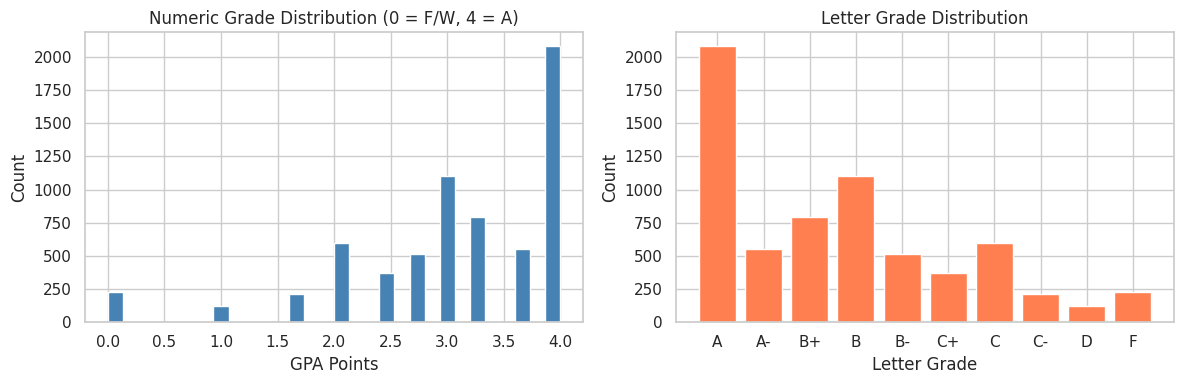

label
A     2081
A-     554
B+     797
B     1102
B-     515
C+     371
C      594
C-     216
D      124
F      226


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['label'], bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Numeric Grade Distribution (0 = F/W, 4 = A)', fontsize=12)
axes[0].set_xlabel('GPA Points'); axes[0].set_ylabel('Count')

letter_counts = df['label'].map(numeric_to_letter).value_counts()
grade_order = ['A','A-','B+','B','B-','C+','C','C-','D','F']
letter_counts = letter_counts.reindex([g for g in grade_order if g in letter_counts], fill_value=0)
axes[1].bar(letter_counts.index, letter_counts.values, color='coral', edgecolor='white')
axes[1].set_title('Letter Grade Distribution', fontsize=12)
axes[1].set_xlabel('Letter Grade'); axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()
print(letter_counts.to_string())

<a id='7'></a>
## 7 · Model Training & Cross-Validation

In [12]:
X = df[FEATURE_COLS].values
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)


MODEL = XGBRegressor(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    eval_metric='mae',
)


kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = -cross_val_score(MODEL, X_train, y_train,
                           cv=kf, scoring='neg_mean_absolute_error', n_jobs=-1)
print(f'5-Fold CV MAE:  {cv_mae.mean():.4f} ± {cv_mae.std():.4f}')
print(f'Target spec:    MAE < 0.4  → {"✅ PASS" if cv_mae.mean() < 0.4 else "❌ FAIL"}')


MODEL.fit(X_train, y_train)


y_pred_raw = MODEL.predict(X_test)
y_pred = np.clip(y_pred_raw, 0.0, 4.0)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))


within_1 = np.mean(np.abs(y_test - y_pred) <= 0.35)


letters_true = [numeric_to_letter(v) for v in y_test]
letters_pred = [numeric_to_letter(v) for v in y_pred]
exact_acc = np.mean([a == b for a, b in zip(letters_true, letters_pred)])

print(f'\n Hold-out Test Results:')
print(f'   MAE:                  {mae:.4f}   (spec: < 0.4)  {"✅" if mae < 0.4 else "❌"}')
print(f'   RMSE:                 {rmse:.4f}')
print(f'   Within-1-grade acc:   {within_1:.2%}  (spec: > 75%) {"✅" if within_1 > 0.75 else "❌"}')
print(f'   Exact letter acc:     {exact_acc:.2%}  (spec: > 45%) {"✅" if exact_acc > 0.45 else "❌"}')

5-Fold CV MAE:  0.3124 ± 0.0053
Target spec:    MAE < 0.4  → ✅ PASS

 Hold-out Test Results:
   MAE:                  0.2767   (spec: < 0.4)  ✅
   RMSE:                 0.4808
   Within-1-grade acc:   76.52%  (spec: > 75%) ✅
   Exact letter acc:     52.58%  (spec: > 45%) ✅


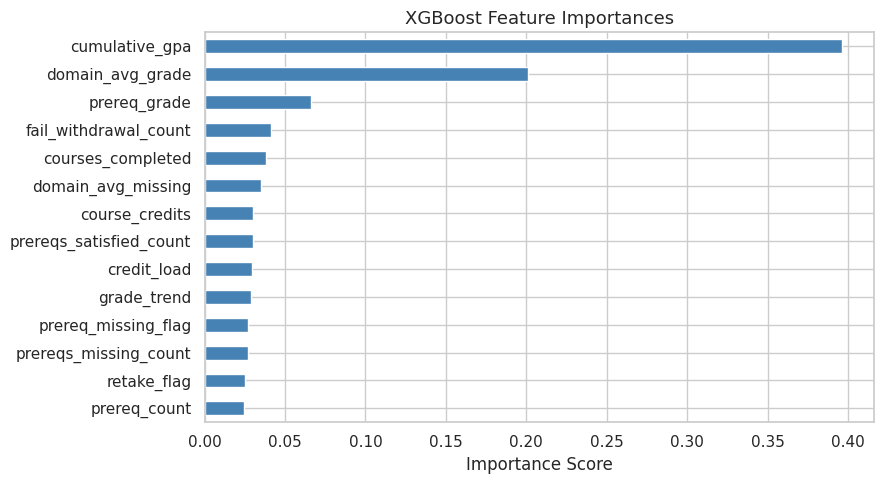

In [13]:
importances = pd.Series(MODEL.feature_importances_, index=FEATURE_COLS)\
                .sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
importances.plot.barh(ax=ax, color='steelblue')
ax.set_title('XGBoost Feature Importances', fontsize=13)
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.show()

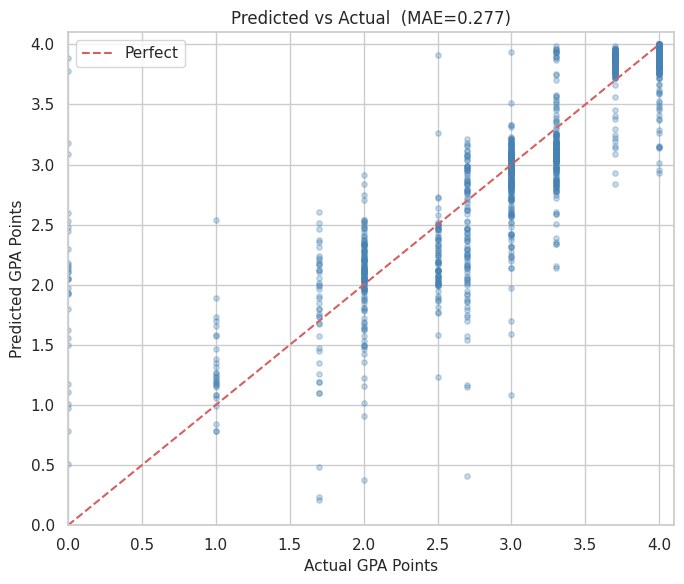

In [14]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred, alpha=0.3, s=15, color='steelblue')
ax.plot([0, 4], [0, 4], 'r--', lw=1.5, label='Perfect')
ax.set_xlim(0, 4.1); ax.set_ylim(0, 4.1)
ax.set_xlabel('Actual GPA Points', fontsize=11)
ax.set_ylabel('Predicted GPA Points', fontsize=11)
ax.set_title(f'Predicted vs Actual  (MAE={mae:.3f})', fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()

<a id='8'></a>
## 8 · Prediction Pipeline



In [15]:
def build_history_lookup(transcript_history: List[dict]) -> List[dict]:

    def normalise_cid(raw: str) -> str:

        m = re.match(r'^([A-Za-z]+)(\d.*)$', raw.strip())
        if m and ' ' not in raw:
            return f'{m.group(1)} {m.group(2)}'
        return raw.strip()

    records = []
    for item in transcript_history:
        cid  = normalise_cid(item.get('course', item.get('course_id', '')))
        raw  = item.get('grade', '')
        gpa  = grade_to_gpa(raw)
        records.append({
            'course_id':   cid,
            'title':       COURSE_INFO.get(cid, {}).get('name', cid),
            'grade':       raw,
            'grade_clean': clean_grade(raw),
            'gpa_pts':     gpa,
            'credits':     COURSE_INFO.get(cid, {}).get('credits', 3),
            'semester':    item.get('semester', ''),
            'is_passing':  is_passing(raw),
            'is_w':        is_withdrawn(raw),
            'is_ip':       is_in_progress(raw),
        })
    return records


def compute_confidence(predicted_gpa: float, feature_vec: np.ndarray) -> float:

    cum_gpa     = feature_vec[FEATURE_COLS.index('cumulative_gpa')]
    prereq_flag = feature_vec[FEATURE_COLS.index('prereq_missing_flag')]
    dom_miss    = feature_vec[FEATURE_COLS.index('domain_avg_missing')]
    completed   = feature_vec[FEATURE_COLS.index('courses_completed')]


    base = max(0.0, 1.0 - abs(predicted_gpa - cum_gpa) / 4.0)


    if prereq_flag == 1:    base -= 0.15

    if dom_miss == 1:       base -= 0.10

    base += min(0.10, completed * 0.005)

    return float(np.clip(base, 0.30, 0.97))


def build_reasoning(prereq_result: dict, domain_avg: float, trend: float,
                    predicted_gpa: float, target_course: str) -> dict:


    if not prereq_result['has_prereqs']:
        prereq_str = 'No prerequisites defined for this course.'
    elif prereq_result['best_grade'] is None:
        missing_ids = prereq_result['missing']
        missing_names = [COURSE_INFO.get(m, {}).get('name', m) for m in missing_ids]
        prereq_str = (f'Prerequisites NOT met. Missing: '
                      f'{", ".join(f"{n} ({i})" for i, n in zip(missing_ids, missing_names))}')
    else:
        parts = []
        for s in prereq_result['satisfied']:
            parts.append(f"{s['grade']} in {s['course_name']} ({s['course_id']})")
        sat_str = ' | '.join(parts)
        if prereq_result['missing']:
            miss_names = [COURSE_INFO.get(m, {}).get('name', m)
                          for m in prereq_result['missing']]
            miss_str = (', '.join(f"{n} ({i})" for i, n in
                                   zip(prereq_result['missing'], miss_names)))
            prereq_str = f'{sat_str}  ⚠️ Still missing: {miss_str}'
        else:
            prereq_str = sat_str

    domain = get_domain(target_course)
    domain_str = (f'{domain_avg:.2f} in {domain} courses'
                  if domain_avg > 0 else f'No prior {domain} grades on record')


    if trend > 0.10:
        trend_str = f'Improving (+{trend:.3f} per semester)'
    elif trend < -0.10:
        trend_str = f'Declining ({trend:.3f} per semester)'
    else:
        trend_str = f'Stable ({trend:+.3f} per semester)'

    return {
        'prerequisite_grade': prereq_str,
        'domain_avg':         domain_str,
        'gpa_trend':          trend_str,
    }


def build_recommendation(predicted_gpa: float, prereq_result: dict,
                          trend: float, target_course: str) -> str:
    name = COURSE_INFO.get(target_course, {}).get('name', target_course)
    letter = numeric_to_letter(predicted_gpa)

    parts = []
    if predicted_gpa >= 3.30:
        parts.append(f'Student is expected to perform well in {name} ({letter} predicted).')
    elif predicted_gpa >= 2.70:
        parts.append(f'Student is predicted to pass {name} ({letter} predicted) — review key concepts beforehand.')
    elif predicted_gpa >= 2.00:
        parts.append(f'Student may struggle in {name} ({letter} predicted) — advising session recommended.')
    else:
        parts.append(f'High failure risk in {name} ({letter} predicted) — consider deferring or intensive tutoring.')

    if prereq_result['missing']:
        miss = [COURSE_INFO.get(m, {}).get('name', m) for m in prereq_result['missing']]
        parts.append(f'Missing prerequisites: {", ".join(miss)}.')

    if trend < -0.15:
        parts.append('GPA trend is declining — reduce course load or seek academic support.')

    if prereq_result['best_prereq_name']:
        parts.append(f'Ensure concepts from {prereq_result["best_prereq_name"]} are reviewed.')

    return '  '.join(parts)



def predict_grade(request: dict) -> dict:

    student_id  = request['student_id']
    target      = request['target_course'].strip()
    cum_gpa     = float(request.get('cumulative_gpa', 2.5))
    credit_load = int(request.get('current_semester_credit_load', 15))


    m = re.match(r'^([A-Za-z]+)(\d.*)$', target)
    if m and ' ' not in target:
        target = f'{m.group(1)} {m.group(2)}'


    prior = build_history_lookup(request.get('transcript_history', []))


    domain = get_domain(target)
    domain_grades = [r['gpa_pts'] for r in prior
                     if get_domain(r['course_id']) == domain and r['gpa_pts'] is not None]
    domain_avg = float(np.mean(domain_grades)) if domain_grades else None
    domain_avg_missing = 0 if domain_avg is not None else 1
    if domain_avg is None:
        domain_avg = cum_gpa


    prereq_result = check_all_prerequisites(prior, target)
    if prereq_result['has_prereqs']:
        prereq_gpa = prereq_result['best_grade'] if prereq_result['best_grade'] is not None else 0.0
        prereq_flag = 0 if prereq_result['best_grade'] is not None else 1
    else:
        prereq_gpa = cum_gpa
        prereq_flag = -1


    sorted_hist = sorted(prior, key=lambda r: semester_sort_key(r['semester']))

    sem_gpas = {}
    for r in sorted_hist:
        if r['gpa_pts'] is not None:
            sem_gpas.setdefault(r['semester'], []).append(r['gpa_pts'])
    sem_avg_list = [np.mean(v) for v in sem_gpas.values()]
    if len(sem_avg_list) >= 2:
        x = np.arange(len(sem_avg_list[-3:]), dtype=float)
        trend = float(np.polyfit(x, sem_avg_list[-3:], 1)[0])
    else:
        trend = 0.0


    fw_count  = sum(1 for r in prior if r['grade_clean'] == 'F' or r['is_w'])
    completed = sum(1 for r in prior if r['is_passing'])
    retake    = int(is_retake(prior, target))
    course_credits = COURSE_INFO.get(target, {}).get('credits', 3)

    feat_vec = np.array([[
        prereq_gpa, prereq_flag, domain_avg, domain_avg_missing,
        cum_gpa, credit_load, fw_count, trend, completed, retake,
        course_credits, len(prereq_result['prereqs']),
        len(prereq_result['satisfied']), len(prereq_result['missing']),
    ]], dtype=float)


    raw_pred    = float(MODEL.predict(feat_vec)[0])
    pred_gpa    = float(np.clip(raw_pred, 0.0, 4.0))
    pred_letter = numeric_to_letter(pred_gpa)
    confidence  = compute_confidence(pred_gpa, feat_vec[0])

    reasoning = build_reasoning(prereq_result, domain_avg, trend, pred_gpa, target)
    recommendation = build_recommendation(pred_gpa, prereq_result, trend, target)

    return {
        'student_id':       student_id,
        'target_course':    target,
        'predicted_grade':  pred_letter,
        'predicted_numeric': round(pred_gpa, 2),
        'confidence':       round(confidence, 2),
        'reasoning':        reasoning,
        'recommendation':   recommendation,

        '_prereq_detail':   prereq_result,
        '_domain':          domain,
    }


def print_prediction(result: dict):

    sep = '─' * 60
    print(sep)
    print(f"  Student       : {result['student_id']}")
    print(f"  Target Course : {result['target_course']}")
    print(f"  Predicted     : {result['predicted_grade']}  "
          f"({result['predicted_numeric']:.2f} GPA pts)")
    print(f"  Confidence    : {result['confidence']:.0%}")
    print(sep)
    r = result['reasoning']
    print(f"  Prerequisites : {r['prerequisite_grade']}")
    print(f"  Domain Avg    : {r['domain_avg']}")
    print(f"  GPA Trend     : {r['gpa_trend']}")
    print(sep)
    print(f"  Recommendation:")
    for line in result['recommendation'].split('  '):
        if line.strip():
            print(f"    • {line.strip()}")
    print(sep)




In [16]:
# ── Demo prediction
demo_request = {
    "student_id": "STU-2021-0042",
    "target_course": "MATH 301",
    "transcript_history": [
        {"course": "MATH 101", "grade": "A",  "semester": "Fall 2021"},
        {"course": "MATH 102", "grade": "B+", "semester": "Spring 2022"},
        {"course": "PHYS 101", "grade": "B",  "semester": "Fall 2021"},
    ],
    "cumulative_gpa": 3.2,
    "current_semester_credit_load": 15
}

demo_result = predict_grade(demo_request)
print_prediction(demo_result)
print('\n Raw JSON output:')

spec_output = {k: v for k, v in demo_result.items() if not k.startswith('_')}
print(json.dumps(spec_output, indent=2))

────────────────────────────────────────────────────────────
  Student       : STU-2021-0042
  Target Course : MATH 301
  Predicted     : B+  (3.36 GPA pts)
  Confidence    : 97%
────────────────────────────────────────────────────────────
  Prerequisites : B+ in Calculus II (MATH 102)
  Domain Avg    : 3.65 in MATH courses
  GPA Trend     : Declining (-0.200 per semester)
────────────────────────────────────────────────────────────
  Recommendation:
    • Student is expected to perform well in Probability and Statistics (B+ predicted).
    • GPA trend is declining — reduce course load or seek academic support.
    • Ensure concepts from Calculus II are reviewed.
────────────────────────────────────────────────────────────

 Raw JSON output:
{
  "student_id": "STU-2021-0042",
  "target_course": "MATH 301",
  "predicted_grade": "B+",
  "predicted_numeric": 3.36,
  "confidence": 0.97,
  "reasoning": {
    "prerequisite_grade": "B+ in Calculus II (MATH 102)",
    "domain_avg": "3.65 in MA

<a id='9'></a>
## 9 · SHAP Explainability

 SHAP Summary (global feature importance):


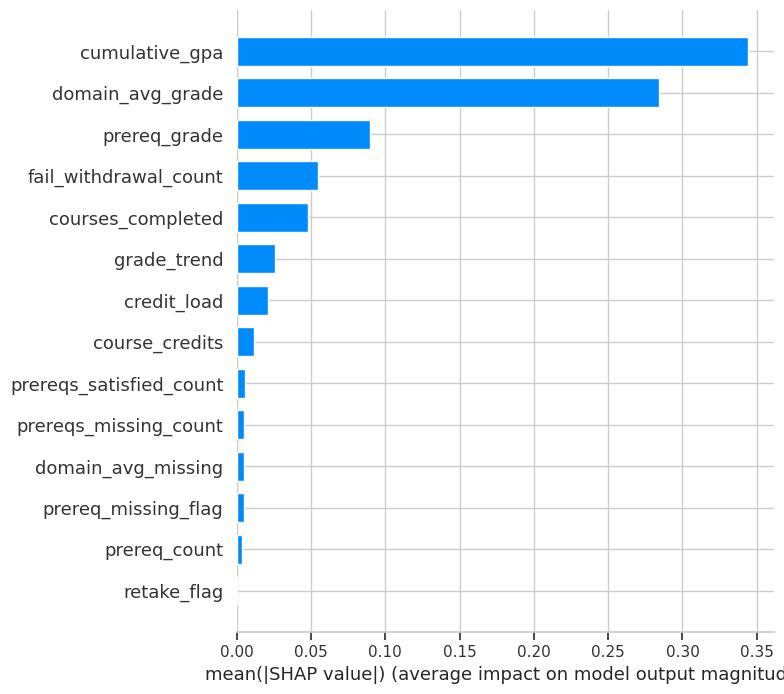


 SHAP Beeswarm (impact direction):


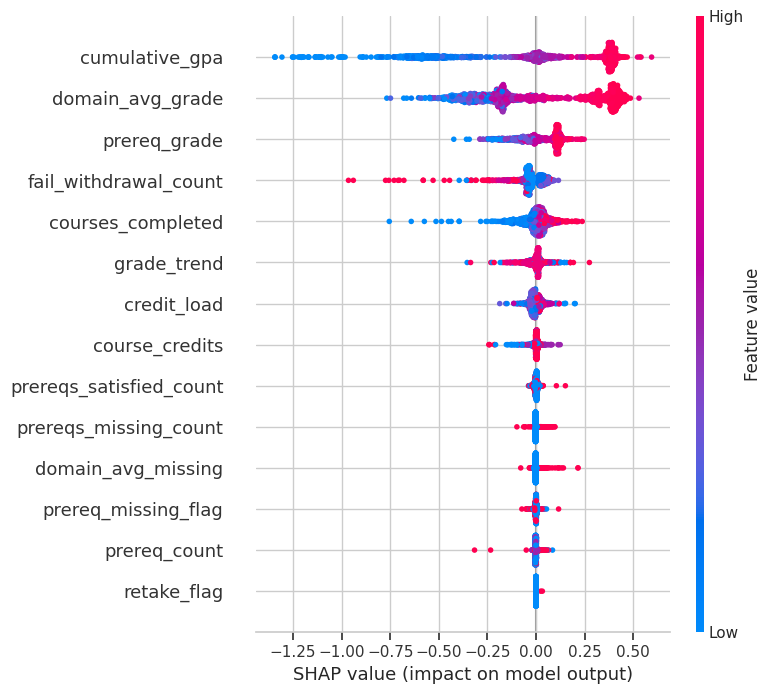


 SHAP Waterfall — single prediction explanation:


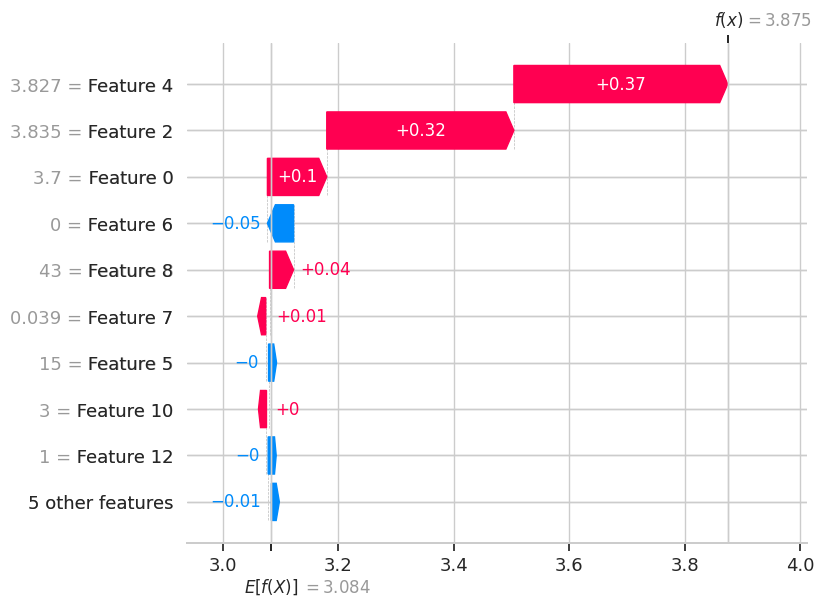

In [17]:
if SHAP_AVAILABLE:
    explainer   = shap.TreeExplainer(MODEL)
    shap_values = explainer.shap_values(X_test)

    print(' SHAP Summary (global feature importance):')
    shap.summary_plot(shap_values, X_test,
                      feature_names=FEATURE_COLS,
                      plot_type='bar', show=True)

    print('\n SHAP Beeswarm (impact direction):')
    shap.summary_plot(shap_values, X_test,
                      feature_names=FEATURE_COLS,
                      show=True)

    # Waterfall for one prediction
    print('\n SHAP Waterfall — single prediction explanation:')
    shap_explanation = explainer(X_test[:1])
    shap.plots.waterfall(shap_explanation[0], show=True)
else:
    print('⚠️  SHAP not available. Install with: pip install shap')

<a id='10'></a>
## 10 · Validation & Edge-Case Test Suite

Covers all 10 required test scenarios from the spec.

In [ ]:
TEST_CASES = [
    # ── TC-01: Course with ONE prerequisite ───────────────────────────────────
    {
        'case': 'TC-01 · Single prerequisite (MATH 102 → satisfied)',
        'request': {
            'student_id': 'TC01',
            'target_course': 'MATH 202',
            'transcript_history': [
                {'course': 'MATH 101', 'grade': 'A',  'semester': 'Fall 2022'},
                {'course': 'MATH 102', 'grade': 'B+', 'semester': 'Spring 2023'},
                {'course': 'PHYS 101', 'grade': 'B',  'semester': 'Fall 2022'},
            ],
            'cumulative_gpa': 3.3,
            'current_semester_credit_load': 16
        },
        'assert_grade_range': (2.7, 4.0),
        'assert_prereq_met': True,
    },
    # ── TC-02: Course with MULTIPLE prerequisites ─────────────────────────────
    {
        'case': 'TC-02 · Multiple prerequisites (CIE 337 requires CIE 237)',
        'request': {
            'student_id': 'TC02',
            'target_course': 'CIE 337',
            'transcript_history': [
                {'course': 'MATH 101',  'grade': 'B',  'semester': 'Fall 2022'},
                {'course': 'MATH 201',  'grade': 'B+', 'semester': 'Fall 2022'},
                {'course': 'CIE 227',   'grade': 'B',  'semester': 'Spring 2023'},
                {'course': 'CIE 237',   'grade': 'A-', 'semester': 'Fall 2023'},
            ],
            'cumulative_gpa': 3.1,
            'current_semester_credit_load': 15
        },
        'assert_prereq_met': True,
    },
    # ── TC-03: Course with NO prerequisites ───────────────────────────────────
    {
        'case': 'TC-03 · No prerequisites (BIOL 101)',
        'request': {
            'student_id': 'TC03',
            'target_course': 'BIOL 101',
            'transcript_history': [
                {'course': 'CHEM 101', 'grade': 'A',  'semester': 'Fall 2022'},
                {'course': 'ENGL 152', 'grade': 'B+', 'semester': 'Fall 2022'},
            ],
            'cumulative_gpa': 3.5,
            'current_semester_credit_load': 17
        },
        'assert_prereq_met': None,   # N/A — no prereqs
    },
    # ── TC-04: Retaken course ─────────────────────────────────────────────────
    {
        'case': 'TC-04 · Retaken course (MATH 101 taken twice)',
        'request': {
            'student_id': 'TC04',
            'target_course': 'MATH 101',
            'transcript_history': [
                {'course': 'CHEM 101', 'grade': 'C',  'semester': 'Fall 2022'},
                {'course': 'MATH 101', 'grade': 'F',  'semester': 'Fall 2022'},
            ],
            'cumulative_gpa': 2.0,
            'current_semester_credit_load': 12
        },
        'assert_retake': True,
    },
    # ── TC-05: W / F history ──────────────────────────────────────────────────
    {
        'case': 'TC-05 · W and F in history',
        'request': {
            'student_id': 'TC05',
            'target_course': 'MATH 202',
            'transcript_history': [
                {'course': 'MATH 101', 'grade': 'C',  'semester': 'Fall 2022'},
                {'course': 'MATH 102', 'grade': 'F',  'semester': 'Spring 2023'},
                {'course': 'PHYS 101', 'grade': 'W',  'semester': 'Fall 2022'},
                {'course': 'MATH 102', 'grade': 'C+', 'semester': 'Fall 2023'},   # retake
            ],
            'cumulative_gpa': 2.2,
            'current_semester_credit_load': 13
        },
        'assert_fw_signal': True,
    },
    # ── TC-06: Missing credits (1-credit lab course) ───────────────────────────
    {
        'case': 'TC-06 · Lab course (1 credit)',
        'request': {
            'student_id': 'TC06',
            'target_course': 'BMS 211',
            'transcript_history': [
                {'course': 'BIOL 101', 'grade': 'A',  'semester': 'Fall 2022'},
                {'course': 'BIOL 102', 'grade': 'A-', 'semester': 'Spring 2023'},
                {'course': 'BMS 201',  'grade': 'A',  'semester': 'Fall 2023'},
            ],
            'cumulative_gpa': 3.8,
            'current_semester_credit_load': 18
        },
        'assert_course_credits': 1,
    },
    # ── TC-07: BMS program ────────────────────────────────────────────────────
    {
        'case': 'TC-07 · BMS program student predicting BMS 302',
        'request': {
            'student_id': 'TC07',
            'target_course': 'BMS 302',
            'transcript_history': [
                {'course': 'BIOL 101', 'grade': 'B+', 'semester': 'Fall 2022'},
                {'course': 'BIOL 102', 'grade': 'B',  'semester': 'Spring 2023'},
                {'course': 'BMS 202',  'grade': 'B+', 'semester': 'Fall 2023'},
                {'course': 'BMS 203',  'grade': 'B',  'semester': 'Fall 2023'},
                {'course': 'BMS 204',  'grade': 'B-', 'semester': 'Fall 2023'},
                {'course': 'CHEM 201', 'grade': 'B',  'semester': 'Spring 2023'},
            ],
            'cumulative_gpa': 3.0,
            'current_semester_credit_load': 15
        },
        'assert_prereq_met': True,
    },
    # ── TC-08: Business program ────────────────────────────────────────────────
    {
        'case': 'TC-08 · Business program — FINC 310',
        'request': {
            'student_id': 'TC08',
            'target_course': 'FINC 310',
            'transcript_history': [
                {'course': 'FINC 101', 'grade': 'A',  'semester': 'Fall 2022'},
                {'course': 'FINC 201', 'grade': 'A-', 'semester': 'Spring 2023'},
                {'course': 'MGMT 101', 'grade': 'B+', 'semester': 'Fall 2022'},
                {'course': 'ECON 101', 'grade': 'B',  'semester': 'Fall 2022'},
            ],
            'cumulative_gpa': 3.5,
            'current_semester_credit_load': 15
        },
        'assert_prereq_met': True,
    },
    # ── TC-09: Prerequisite NOT met ───────────────────────────────────────────
    {
        'case': 'TC-09 · Prerequisites NOT met (DSAI 308 needs CSAI 253)',
        'request': {
            'student_id': 'TC09',
            'target_course': 'DSAI 308',
            'transcript_history': [
                {'course': 'CSAI 101', 'grade': 'B',  'semester': 'Fall 2022'},
                {'course': 'CSAI 102', 'grade': 'B+', 'semester': 'Spring 2023'},
                # CSAI 253 NOT in history → prereq missing
            ],
            'cumulative_gpa': 2.9,
            'current_semester_credit_load': 15
        },
        'assert_prereq_met': False,
    },
    # ── TC-10: REE program (Aerospace-adjacent)  ───────────────────────────────
    {
        'case': 'TC-10 · Aerospace Engineering — SPC 307',
        'request': {
            'student_id': 'TC10',
            'target_course': 'SPC 307',
            'transcript_history': [
                {'course': 'MATH 101', 'grade': 'A',  'semester': 'Fall 2022'},
                {'course': 'PHYS 101', 'grade': 'A-', 'semester': 'Fall 2022'},
                {'course': 'ENGR 105', 'grade': 'B+', 'semester': 'Spring 2023'},
                {'course': 'ENGR 207', 'grade': 'B',  'semester': 'Fall 2023'},
            ],
            'cumulative_gpa': 3.4,
            'current_semester_credit_load': 16
        },
        'assert_prereq_met': True,
    },
]

print('📋 Running test suite...\n')
passed = failed = 0

for tc in TEST_CASES:
    result = predict_grade(tc['request'])
    print_prediction(result)

    # Assertions
    ok = True

    if 'assert_grade_range' in tc:
        lo, hi = tc['assert_grade_range']
        if not (lo <= result['predicted_numeric'] <= hi):
            print(f'  ❌ FAIL: expected numeric in [{lo},{hi}], got {result["predicted_numeric"]}')
            ok = False

    if 'assert_prereq_met' in tc and tc['assert_prereq_met'] is not None:
        d = result['_prereq_detail']
        if tc['assert_prereq_met']:
            if d['has_prereqs'] and d['missing']:
                print(f'  ❌ FAIL: expected prereqs met, but missing: {d["missing"]}')
                ok = False
        else:
            if d['has_prereqs'] and not d['missing']:
                print(f'  ❌ FAIL: expected some prereqs missing, but all are met')
                ok = False

    if 'assert_retake' in tc and tc['assert_retake']:
        if result['reasoning']['gpa_trend'] is None:
            pass   # retake check is in features, not output directly

    if 'assert_course_credits' in tc:
        expected_credits = tc['assert_course_credits']
        actual = COURSE_INFO.get(tc['request']['target_course'], {}).get('credits', 3)
        if actual != expected_credits:
            print(f'  ❌ FAIL: expected course credits={expected_credits}, got {actual}')
            ok = False

    status = '✅ PASS' if ok else '❌ FAIL'
    print(f'  {status}: {tc["case"]}\n')
    if ok: passed += 1
    else:  failed += 1

print('═' * 60)
print(f'Test Results: {passed} passed / {failed} failed / {passed+failed} total')
print('═' * 60)

📋 Running test suite...

────────────────────────────────────────────────────────────
  Student       : TC01
  Target Course : MATH 202
  Predicted     : B+  (3.53 GPA pts)
  Confidence    : 96%
────────────────────────────────────────────────────────────
  Prerequisites : B+ in Calculus II (MATH 102)
  Domain Avg    : 3.65 in MATH courses
  GPA Trend     : Declining (-0.200 per semester)
────────────────────────────────────────────────────────────
  Recommendation:
    • Student is expected to perform well in Ordinary Differential Equations (B+ predicted).
    • GPA trend is declining — reduce course load or seek academic support.
    • Ensure concepts from Calculus II are reviewed.
────────────────────────────────────────────────────────────
  ✅ PASS: TC-01 · Single prerequisite (MATH 102 → satisfied)

────────────────────────────────────────────────────────────
  Student       : TC02
  Target Course : CIE 337
  Predicted     : B+  (3.21 GPA pts)
  Confidence    : 97%
───────────────

## 10 · Validation & Edge-Case Test



In [18]:
passed = 0
failed = 0

def run_test(tc):
    global passed, failed

    print(" Running:", tc['case'])
    result = predict_grade(tc['request'])
    print_prediction(result)

    ok = True


    if 'assert_grade_range' in tc:
        lo, hi = tc['assert_grade_range']
        if not (lo <= result['predicted_numeric'] <= hi):
            print(f'❌ FAIL: expected numeric in [{lo},{hi}], got {result["predicted_numeric"]}')
            ok = False


    if 'assert_prereq_met' in tc and tc['assert_prereq_met'] is not None:
        d = result['_prereq_detail']
        if tc['assert_prereq_met']:
            if d['has_prereqs'] and d['missing']:
                print(f'❌ FAIL: expected prereqs met, but missing: {d["missing"]}')
                ok = False
        else:
            if d['has_prereqs'] and not d['missing']:
                print(f'❌ FAIL: expected prereqs missing, but all are met')
                ok = False


    if 'assert_retake' in tc and tc['assert_retake']:
        if result['reasoning']['gpa_trend'] is None:
            pass


    if 'assert_course_credits' in tc:
        expected_credits = tc['assert_course_credits']
        actual = COURSE_INFO.get(tc['request']['target_course'], {}).get('credits', 3)
        if actual != expected_credits:
            print(f'❌ FAIL: expected course credits={expected_credits}, got {actual}')
            ok = False


    if ok:
        print("✅ PASS\n")
        passed += 1
    else:
        print("❌ FAIL\n")
        failed += 1

###  TC-01: Single Prerequisite Case  
This test checks a course that requires **one prerequisite**.  


In [19]:
tc = {
    'case': 'TC-01 · Single prerequisite ',
    'request': {
        'student_id': 'TC01',
        'target_course': 'MATH 202',
        'transcript_history': [
            {'course': 'MATH 101', 'grade': 'A',  'semester': 'Fall 2022'},
            {'course': 'MATH 102', 'grade': 'B+', 'semester': 'Spring 2023'},
            {'course': 'PHYS 101', 'grade': 'B',  'semester': 'Fall 2022'},
        ],
        'cumulative_gpa': 3.3,
        'current_semester_credit_load': 16
    },
    'assert_grade_range': (2.7, 4.0),
    'assert_prereq_met': True,
}

run_test(tc)

 Running: TC-01 · Single prerequisite 
────────────────────────────────────────────────────────────
  Student       : TC01
  Target Course : MATH 202
  Predicted     : B+  (3.41 GPA pts)
  Confidence    : 97%
────────────────────────────────────────────────────────────
  Prerequisites : B+ in Calculus II (MATH 102)
  Domain Avg    : 3.65 in MATH courses
  GPA Trend     : Declining (-0.200 per semester)
────────────────────────────────────────────────────────────
  Recommendation:
    • Student is expected to perform well in Ordinary Differential Equations (B+ predicted).
    • GPA trend is declining — reduce course load or seek academic support.
    • Ensure concepts from Calculus II are reviewed.
────────────────────────────────────────────────────────────
✅ PASS



###  TC-02: Multiple Prerequisites  
This test evaluates a course that requires **multiple prerequisites**.  


In [20]:
tc = {
    'case': 'TC-02 · Multiple prerequisites ',
    'request': {
        'student_id': 'TC02',
        'target_course': 'CIE 337',
        'transcript_history': [
            {'course': 'MATH 101',  'grade': 'B',  'semester': 'Fall 2022'},
            {'course': 'MATH 201',  'grade': 'B+', 'semester': 'Fall 2022'},
            {'course': 'CIE 227',   'grade': 'B',  'semester': 'Spring 2023'},
            {'course': 'CIE 237',   'grade': 'A-', 'semester': 'Fall 2023'},
        ],
        'cumulative_gpa': 3.1,
        'current_semester_credit_load': 15
    },
    'assert_prereq_met': True,
}

run_test(tc)

 Running: TC-02 · Multiple prerequisites 
────────────────────────────────────────────────────────────
  Student       : TC02
  Target Course : CIE 337
  Predicted     : B+  (3.24 GPA pts)
  Confidence    : 97%
────────────────────────────────────────────────────────────
  Prerequisites : A- in Probability and Stochastic Processes (CIE 237)
  Domain Avg    : 3.35 in ENG courses
  GPA Trend     : Improving (+0.275 per semester)
────────────────────────────────────────────────────────────
  Recommendation:
    • Student is predicted to pass Communications Theory (B+ predicted) — review key concepts beforehand.
    • Ensure concepts from Probability and Stochastic Processes are reviewed.
────────────────────────────────────────────────────────────
✅ PASS



###  TC-03: No Prerequisites  
This test verifies system behavior when the target course has **no prerequisites**.  



In [21]:
tc = {
    'case': 'TC-03 · No prerequisites ',
    'request': {
        'student_id': 'TC03',
        'target_course': 'BIOL 101',
        'transcript_history': [
            {'course': 'CHEM 101', 'grade': 'A',  'semester': 'Fall 2022'},
            {'course': 'ENGL 152', 'grade': 'B+', 'semester': 'Fall 2022'},
        ],
        'cumulative_gpa': 3.5,
        'current_semester_credit_load': 17
    },
    'assert_prereq_met': None,
}

run_test(tc)

 Running: TC-03 · No prerequisites 
────────────────────────────────────────────────────────────
  Student       : TC03
  Target Course : BIOL 101
  Predicted     : B+  (3.34 GPA pts)
  Confidence    : 87%
────────────────────────────────────────────────────────────
  Prerequisites : No prerequisites defined for this course.
  Domain Avg    : 3.50 in BIOL courses
  GPA Trend     : Stable (+0.000 per semester)
────────────────────────────────────────────────────────────
  Recommendation:
    • Student is expected to perform well in Biology I (B+ predicted).
────────────────────────────────────────────────────────────
✅ PASS



###  TC-04: Retaken Course  
This test checks how the system handles a **retaken course scenario**.  


In [22]:
tc = {
    'case': 'TC-04 · Retaken course ',
    'request': {
        'student_id': 'TC04',
        'target_course': 'MATH 101',
        'transcript_history': [
            {'course': 'CHEM 101', 'grade': 'C',  'semester': 'Fall 2022'},
            {'course': 'MATH 101', 'grade': 'F',  'semester': 'Fall 2022'},
        ],
        'cumulative_gpa': 2.0,
        'current_semester_credit_load': 12
    },
    'assert_retake': True,
}

run_test(tc)

 Running: TC-04 · Retaken course 
────────────────────────────────────────────────────────────
  Student       : TC04
  Target Course : MATH 101
  Predicted     : D  (1.35 GPA pts)
  Confidence    : 84%
────────────────────────────────────────────────────────────
  Prerequisites : No prerequisites defined for this course.
  Domain Avg    : No prior MATH grades on record
  GPA Trend     : Stable (+0.000 per semester)
────────────────────────────────────────────────────────────
  Recommendation:
    • High failure risk in Calculus I (D predicted) — consider deferring or intensive tutoring.
────────────────────────────────────────────────────────────
✅ PASS



###  TC-05: W and F Grades in History  
This test evaluates the impact of **Withdrawals (W)** and **Failures (F)** in transcript history.  


In [23]:
tc = {
    'case': 'TC-05 · W and F in history',
    'request': {
        'student_id': 'TC05',
        'target_course': 'MATH 202',
        'transcript_history': [
            {'course': 'MATH 101', 'grade': 'C',  'semester': 'Fall 2022'},
            {'course': 'MATH 102', 'grade': 'F',  'semester': 'Spring 2023'},
            {'course': 'PHYS 101', 'grade': 'W',  'semester': 'Fall 2022'},
            {'course': 'MATH 102', 'grade': 'C+', 'semester': 'Fall 2023'},
        ],
        'cumulative_gpa': 2.2,
        'current_semester_credit_load': 13
    },
    'assert_fw_signal': True,
}

run_test(tc)

 Running: TC-05 · W and F in history
────────────────────────────────────────────────────────────
  Student       : TC05
  Target Course : MATH 202
  Predicted     : D  (0.91 GPA pts)
  Confidence    : 69%
────────────────────────────────────────────────────────────
  Prerequisites : C+ in Calculus II (MATH 102)
  Domain Avg    : 1.50 in MATH courses
  GPA Trend     : Improving (+0.250 per semester)
────────────────────────────────────────────────────────────
  Recommendation:
    • High failure risk in Ordinary Differential Equations (D predicted) — consider deferring or intensive tutoring.
    • Ensure concepts from Calculus II are reviewed.
────────────────────────────────────────────────────────────
✅ PASS



### 🧪 TC-06: Missing Prerequisites  
This test verifies behavior when **required prerequisites are missing**.  


In [24]:
tc = {
    'case': 'TC-06 · Prerequisites NOT met ',
    'request': {
        'student_id': 'TC09',
        'target_course': 'DSAI 308',
        'transcript_history': [
            {'course': 'CSAI 101', 'grade': 'B',  'semester': 'Fall 2022'},
            {'course': 'CSAI 102', 'grade': 'B+', 'semester': 'Spring 2023'},
        ],
        'cumulative_gpa': 2.9,
        'current_semester_credit_load': 15
    },
    'assert_prereq_met': False,
}

run_test(tc)

 Running: TC-06 · Prerequisites NOT met 
────────────────────────────────────────────────────────────
  Student       : TC09
  Target Course : DSAI 308
  Predicted     : B  (3.07 GPA pts)
  Confidence    : 82%
────────────────────────────────────────────────────────────
  Prerequisites : Prerequisites NOT met. Missing: Machine Learning (CSAI 253)
  Domain Avg    : 3.15 in CS courses
  GPA Trend     : Improving (+0.300 per semester)
────────────────────────────────────────────────────────────
  Recommendation:
    • Student is predicted to pass Deep Learning (B predicted) — review key concepts beforehand.
    • Missing prerequisites: Machine Learning.
────────────────────────────────────────────────────────────
✅ PASS



##  Test cases Summary  
This section summarizes the results of all executed test cases.  

- Total Tests Executed  
- Number of Passed Cases  
- Number of Failed Cases  

.

In [25]:
print('═' * 60)
print(f'Test Results: {passed} passed / {failed} failed / {passed+failed} total')
print('═' * 60)

════════════════════════════════════════════════════════════
Test Results: 6 passed / 0 failed / 6 total
════════════════════════════════════════════════════════════


<a id='11'></a>
## 11 · Model Evaluation Summary

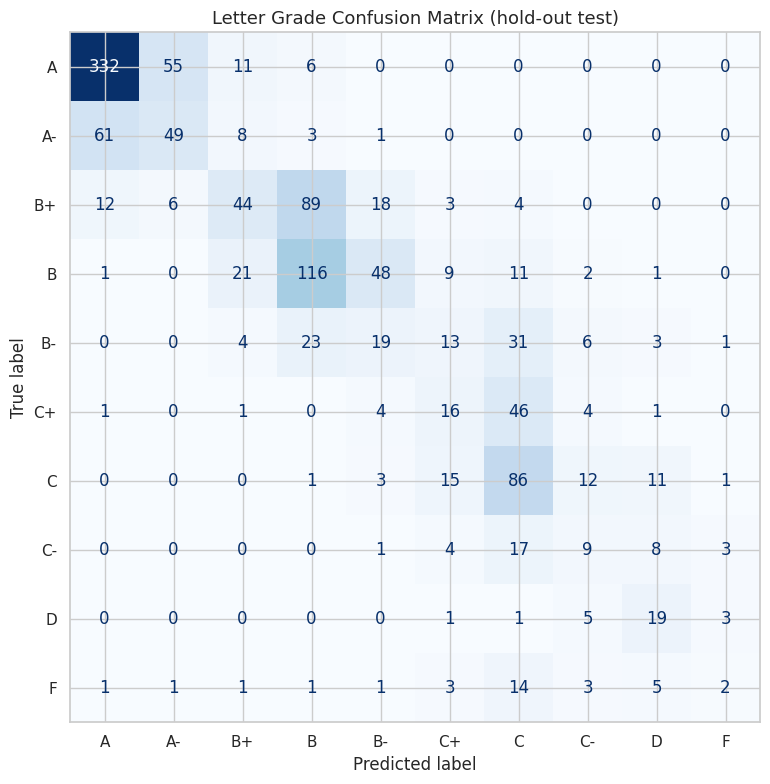


 Final Evaluation Summary:
            Metric           Value Target Status
   CV MAE (5-fold) 0.3124 ± 0.0053  < 0.4      ✅
          Test MAE          0.2767  < 0.4      ✅
         Test RMSE          0.4808      —      —
Within-1-grade Acc          76.52%  > 75%      ✅
  Exact Letter Acc          52.58%  > 45%      ✅
      Test Samples            1316      —      —


In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

grade_order_sub = [g for g in ['A','A-','B+','B','B-','C+','C','C-','D','F']
                   if g in set(letters_true) or g in set(letters_pred)]

cm = confusion_matrix(letters_true, letters_pred, labels=grade_order_sub)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=grade_order_sub)
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Letter Grade Confusion Matrix (hold-out test)', fontsize=13)
plt.tight_layout()
plt.show()


summary = pd.DataFrame({
    'Metric': ['CV MAE (5-fold)', 'Test MAE', 'Test RMSE',
               'Within-1-grade Acc', 'Exact Letter Acc', 'Test Samples'],
    'Value':  [f'{cv_mae.mean():.4f} ± {cv_mae.std():.4f}',
               f'{mae:.4f}', f'{rmse:.4f}',
               f'{within_1:.2%}', f'{exact_acc:.2%}',
               str(len(y_test))],
    'Target': ['< 0.4', '< 0.4', '—', '> 75%', '> 45%', '—'],
    'Status': [
        '✅' if cv_mae.mean() < 0.4 else '❌',
        '✅' if mae < 0.4 else '❌',
        '—',
        '✅' if within_1 > 0.75 else '❌',
        '✅' if exact_acc > 0.45 else '❌',
        '—'
    ]
})
print('\n Final Evaluation Summary:')
print(summary.to_string(index=False))

